# **SWaT 2015 (A1/A2) zero-day detection — v3: state + dynamics TabPFN teachers, synthetic-corruption distillation, adaptive thresholds**

v3 keeps the leakage-free protocol of v1/v2 (Plan §1) and adds the feature design of Plan §3 plus the fixes that the v2 run (`2107c339a8`) pointed to.

#### What v2 showed (CAL 1% threshold, TEST attack period)
| method | ROC-AUC | test FPR | recall | attacks | what went wrong |
|---|---|---|---|---|---|
| TabPFN detrend 600 s (primary) | 0.723 | 0.13 | 0.23 | 24/35 | Catches the first ~10 min of an attack (recall 0.64), then misses the sustained phase (0.07). Once the trailing mean catches up, the detrended values go *quiet*. |
| TabPFN level | 0.912 | 0.63 | 0.95 | 35/35 | Ranks well but saturates at ≈12.8 out of support. False alarms reach 99% per day by 2 Jan (drift). |
| TabPFN fused | 0.917 | 0.32 | 0.92 | 30/35 | Best TabPFN result: onset (detrend) + sustained (level). |
| GMM level / detrend | 0.914 / 0.869 | 0.54 / 0.15 | 0.92 / 0.88 | 33 / 25 | **TabPFN level = GMM level** (ΔAUC −0.003, CI [−0.03, 0.02]). The GMM still catches the "quiet" sustained phase through its joint covariance. |
| CatBoost / LightGBM-linear | 0.42 / 0.44 | 0.04 | 0.06 / 0.15 | 18 / 22 | They learned "quiet input ⇒ normal" from a detrend teacher, which is the wrong target. They copy the teacher well on normal rows (Spearman 0.92) and invert it on attacks. |

#### Changes in v3
| # | Change | Why | Where |
|---|---|---|---|
| 1 | **Three views, one TabPFN teacher each:** **state** = sensors without AIT + non-constant actuators; **detrend** = sensors − 600 s trailing mean (onsets); **dynamics** = log rolling std over 60 s ("is the plant moving?") | The sustained phase is a *combination* of a held state and frozen dynamics. Actuators are the conditioning variables of Plan §3. | §3, Part B |
| 2 | **Primary teacher = fused (mean of the three CAL-calibrated views)**, max fusion reported too | v2: fusing onset and level evidence gave the best TabPFN AUC | B1 |
| 3 | **Surrogates distil the fused teacher** from **all views' features** | v2's surrogate target (detrend) carried the blind spot | Part C |
| 4 | **Teacher-scored synthetic corruptions** added to distillation: stuck sensor, offset, ramp, whole-stage hold, actuator flip. Normal-only vs. +synthetic is the Plan §5 ablation. | Normal-only distillation never shows the surrogate a high-score region | §4.1, Part C |
| 5 | **More chain-rule permutations** (2 → 4) | Smoother density, less sensitivity to the feature order | §0.1 |
| 6 | **Adaptive threshold** (label-free, online): each score is normalised by the robust median/IQR of the previous 24 h, excluding the last hour, and thresholded at the CAL quantile of the normalised score. Reported next to the static CAL threshold for every method. | No static threshold survived the 5-day drift in v1/v2 | §0.2, E1, E6, F |
| 7 | **Final ROC/AUC evaluation** of TabPFN teacher vs. GMM baseline vs. surrogate: AUC and AP with block-bootstrap CIs, partial AUC, TPR at 1% FPR, paired ΔAUC | Requested headline comparison | §F |
| 8 | **Figures**: every figure is saved at **600 dpi** to `output-figures/<name>_v3.png`; Spearman heatmap with small annotations | Paper-ready output | everywhere |

Diagnostic only, not a detector: §3 counts how many attacks put an actuator in a state **never seen in FIT** (e.g. a backup pump switched on). Constant-in-FIT actuators cannot be modelled by a density, so they are excluded from the views and only reported.

#### Evaluation protocol (Plan §1, unchanged)
Chronological split (fit early normal → calibrate later normal → test the attack period). 30-step post-attack guard on FIT/CAL only. One threshold rule for all methods. Block-bootstrap CIs, DeLong tests, several context seeds, event-level metrics. Every table in §E/§F is rebuilt from saved files.

In [1]:
# Uncomment if the environment is missing dependencies.
# %pip install -q "tabpfn>=9.2" "tabpfn-extensions[unsupervised]>=0.6" catboost lightgbm scikit-learn pandas pyarrow numpy scipy matplotlib seaborn torch python-dotenv

## **0. Setup, configuration and versioning**

Run this section first in every session. It is cheap: no data is loaded and no model is fitted.

In [2]:
import copy
import gc
import hashlib
import importlib.metadata as importlib_metadata
import json
import os
import platform
import random
import re
import time
import warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from scipy import stats
from sklearn.metrics import (
    average_precision_score,
    confusion_matrix,
    precision_recall_curve,
    roc_auc_score,
    roc_curve,
)
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
import catboost
from catboost import CatBoostRegressor, Pool
import lightgbm as lgb
import tabpfn
from tabpfn import TabPFNClassifier, TabPFNRegressor
from tabpfn_extensions.unsupervised import TabPFNUnsupervisedModel
from dotenv import load_dotenv

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))
print("tabpfn", tabpfn.__version__, "| catboost", catboost.__version__, "| lightgbm", lgb.__version__, "| torch", torch.__version__)

load_dotenv("/home/jaume/_DEVELOPMENT/_projects/secrets.env")   # adjust the path to where the file is
assert os.environ.get("TABPFN_TOKEN"), "TABPFN_TOKEN not found in secrets.env"

Device: cuda (NVIDIA GB10)
tabpfn 9.2.0 | catboost 1.2.10 | lightgbm 4.6.0 | torch 2.12.0+cu130


### **0.1 Configuration**

Each block has its own fingerprint, so changing one never recomputes the expensive parts upstream:

| block | changes … | cached in |
|---|---|---|
| `TEACHER_CONFIG` | data, split, feature views, TabPFN settings | `teacher/<teacher_fp>/` (one file per view × seed) |
| `SYNTH_CONFIG` | synthetic corruptions (scored by the same teachers) | `teacher/<teacher_fp>/synthetic/<synth_fp>/` |
| `SURROGATE_CONFIG` | surrogate target, training sets, models | `surrogates/<surrogate_fp>/` |
| `AE_CONFIG`, `GMM_CONFIG`, `EVAL_CONFIG` | baselines and evaluation | run directory (seconds to minutes) |

Figures go to `output-figures/<name>_v3.png` at 600 dpi.

Set `SMOKE_TEST = True` for a quick end-to-end check with tiny sizes. Smoke results go to a separate run directory and are not meaningful.

In [3]:
RUN_ID = "SWaT_A1A2-full-pipeline-v3"
FIG_VERSION = "v3"
FIG_DPI = 600
SMOKE_TEST = False

DATA_DIR = Path("scada-data/SWaT-A1-A2/clean")
RESULTS_ROOT = Path("results")
FIG_DIR = Path("output-figures")

TEACHER_CONFIG = {
    "dataset": "SWaT 2015 (A1/A2): SWaT_Dataset_Normal_v1 + SWaT_Dataset_Attack_v0",
    # Chronological split (Plan §1)
    "drop_warmup": True,
    "fit_fraction": 0.70,
    "fit_cal_gap_rows": 3600,
    "post_attack_guard_steps": 30,
    "cal_stride": 10,
    "test_stride": 10,                    # must equal cal_stride (adaptive threshold)
    # Feature views (Plan §3)
    "exclude_prefixes": ["AIT"],          # drifting chemical analysers
    "include_actuators": True,            # non-constant actuators join the state view
    "detrend_window_s": 600,              # causal trailing mean (onsets)
    "dynamics_window_s": 60,              # causal rolling std (frozen / moving)
    "views": ["state", "detrend", "dynamics"],
    # TabPFN density teacher
    "teacher_seeds": [42, 43, 44],
    "context_size": 5000,
    "n_estimators": 1,
    "n_permutations": 4,                  # v2: 2
    "score_batch_size": 4096,
    "distil_stride": 10,
    "distil_max_rows": 20000,
}
SYNTH_CONFIG = {
    "enabled": True,
    "n_windows": 160,
    "duration_s": [300, 1800],
    "row_stride": 10,
    "kinds": ["stuck", "offset", "ramp", "stage_hold", "actuator_flip"],
    "offset_iqr": [2.0, 6.0],             # offset / ramp size in FIT IQRs
    "eval_fraction": 0.2,                 # share of windows held out for early stopping
    "seed": 7,
}
SURROGATE_CONFIG = {
    "distil_target": "teacher_fused",     # the primary teacher
    "target": "rank",                     # empirical CDF of the teacher score (v2: rank ≈ raw)
    "train_sets": ["normal", "synthetic"],  # normal-only vs. normal + synthetic (Plan §5 ablation)
    "primary": "lightgbm_linear|synthetic",
    "eval_fraction": 0.15,                # chronological tail of the normal distillation rows
    "catboost": {"loss_function": "RMSE", "iterations": 4000, "learning_rate": 0.05, "depth": 8,
                 "l2_leaf_reg": 3.0, "early_stopping_rounds": 300, "random_seed": 42},
    "lightgbm": {"objective": "regression", "linear_tree": True, "linear_lambda": 1.0,
                 "n_estimators": 4000, "learning_rate": 0.03, "num_leaves": 31, "min_child_samples": 100,
                 "subsample": 0.9, "subsample_freq": 1, "colsample_bytree": 0.9, "reg_lambda": 1.0,
                 "early_stopping_rounds": 300, "random_state": 42},
}
AE_CONFIG = {"feature_views": ["state", "detrend", "dynamics"], "batch_size": 1024, "max_epochs": 60,
             "patience": 7, "learning_rate": 1e-3, "noise_std": 0.03, "val_fraction": 0.10, "seed": 42}
GMM_CONFIG = {"views": ["state", "detrend", "dynamics"], "components_grid": [4, 8, 16, 32], "covariance": "full",
              "reg_covar": 1e-4, "fit_stride": 20, "seed": 42}
EVAL_CONFIG = {
    "primary_teacher": "teacher_fused",
    "target_fpr": 0.01,
    "fpr_grid": [0.005, 0.01, 0.02, 0.05],
    "bootstrap_block_rows": 360,          # 360 rows x 10 s = 1 hour blocks
    "bootstrap_repeats": 1000,
    "bootstrap_seed": 2026,
    "adaptive_window_s": 86400,           # trailing 24 h baseline
    "adaptive_gap_s": 3600,               # ... ending 1 h before the scored row
    "adaptive_min_history_s": 7200,
    "pauc_max_fpr": 0.10,
    "onset_s": 600,                       # attack phase split: first 10 min vs. sustained
}

if SMOKE_TEST:
    RUN_ID += "-smoke"
    FIG_VERSION += "-smoke"
    TEACHER_CONFIG.update({"teacher_seeds": [42, 43], "context_size": 500, "cal_stride": 40, "test_stride": 40,
                           "distil_max_rows": 2000, "n_permutations": 2})
    SYNTH_CONFIG["n_windows"] = 20
    SURROGATE_CONFIG["catboost"]["iterations"] = 300
    SURROGATE_CONFIG["lightgbm"]["n_estimators"] = 300
    AE_CONFIG["max_epochs"] = 3
    GMM_CONFIG["components_grid"] = [4]
    EVAL_CONFIG["bootstrap_repeats"] = 50
    EVAL_CONFIG["bootstrap_block_rows"] = 90


def fingerprint(obj):
    return hashlib.sha1(json.dumps(obj, sort_keys=True).encode()).hexdigest()[:10]


TEACHER_FINGERPRINT = fingerprint(TEACHER_CONFIG)
SYNTH_FINGERPRINT = fingerprint([TEACHER_CONFIG, SYNTH_CONFIG])
SURROGATE_FINGERPRINT = fingerprint([TEACHER_FINGERPRINT, SYNTH_FINGERPRINT, SURROGATE_CONFIG])
RUN_FINGERPRINT = fingerprint([TEACHER_CONFIG, SYNTH_CONFIG, SURROGATE_CONFIG, AE_CONFIG, GMM_CONFIG, EVAL_CONFIG])
RUN_DIR = RESULTS_ROOT / RUN_ID
TEACHER_DIR = RUN_DIR / "teacher" / TEACHER_FINGERPRINT
SYNTH_DIR = TEACHER_DIR / "synthetic" / SYNTH_FINGERPRINT
SURROGATE_DIR = RUN_DIR / "surrogates" / SURROGATE_FINGERPRINT
for d in [RUN_DIR, TEACHER_DIR / "members", SYNTH_DIR, SURROGATE_DIR, FIG_DIR]:
    d.mkdir(parents=True, exist_ok=True)


def package_version(name):
    try:
        return importlib_metadata.version(name)
    except importlib_metadata.PackageNotFoundError:
        return "not installed"


ENVIRONMENT = {
    "python": platform.python_version(), "platform": platform.platform(), "device": DEVICE,
    "gpu": torch.cuda.get_device_name(0) if DEVICE == "cuda" else None,
    "tabpfn": tabpfn.__version__, "tabpfn_extensions": package_version("tabpfn-extensions"),
    "torch": torch.__version__, "catboost": catboost.__version__, "lightgbm": lgb.__version__,
    "scikit-learn": package_version("scikit-learn"), "pandas": pd.__version__, "numpy": np.__version__,
}
config_path = RUN_DIR / "config.json"
teacher_config_path = TEACHER_DIR / "teacher_config.json"
previous_teacher = json.loads(teacher_config_path.read_text()) if teacher_config_path.exists() else {}
teacher_config_path.write_text(json.dumps({
    "teacher_config": TEACHER_CONFIG, "teacher_fingerprint": TEACHER_FINGERPRINT,
    "environment": previous_teacher.get("environment", ENVIRONMENT),
    "tabpfn_checkpoint": previous_teacher.get("tabpfn_checkpoint"),
    "created": previous_teacher.get("created", datetime.now().isoformat(timespec="seconds")),
}, indent=2))
config_path.write_text(json.dumps({
    "run_id": RUN_ID, "run_fingerprint": RUN_FINGERPRINT, "teacher_fingerprint": TEACHER_FINGERPRINT,
    "synth_fingerprint": SYNTH_FINGERPRINT, "surrogate_fingerprint": SURROGATE_FINGERPRINT,
    "teacher_dir": TEACHER_DIR.as_posix(), "synth_dir": SYNTH_DIR.as_posix(), "surrogate_dir": SURROGATE_DIR.as_posix(),
    "teacher_config": TEACHER_CONFIG, "synth_config": SYNTH_CONFIG, "surrogate_config": SURROGATE_CONFIG,
    "ae_config": AE_CONFIG, "gmm_config": GMM_CONFIG, "eval_config": EVAL_CONFIG,
    "figures": {"dir": FIG_DIR.as_posix(), "version": FIG_VERSION, "dpi": FIG_DPI},
    "environment": ENVIRONMENT, "written": datetime.now().isoformat(timespec="seconds"),
}, indent=2))

print(f"RUN_ID:                {RUN_ID}")
print(f"Run fingerprint:       {RUN_FINGERPRINT}")
print(f"Teacher fingerprint:   {TEACHER_FINGERPRINT}  -> {TEACHER_DIR}")
print(f"Synthetic fingerprint: {SYNTH_FINGERPRINT}")
print(f"Surrogate fingerprint: {SURROGATE_FINGERPRINT}")
print(f"Figures:               {FIG_DIR}/<name>_{FIG_VERSION}.png @ {FIG_DPI} dpi")

RUN_ID:                SWaT_A1A2-full-pipeline-v3
Run fingerprint:       bf936a2bb2
Teacher fingerprint:   fe81f1e75c  -> results/SWaT_A1A2-full-pipeline-v3/teacher/fe81f1e75c
Synthetic fingerprint: 64ab1c0b30
Surrogate fingerprint: f487a86a7d
Figures:               output-figures/<name>_v3.png @ 600 dpi


### **0.2 Shared helpers**

Same definitions as v2, plus:
- `save_fig`: writes `output-figures/<name>_v3.png` at 600 dpi.
- `adaptive_normalise`: the label-free adaptive threshold (change 6).
- `tpr_at_fpr`: the ROC operating point for the final evaluation.

Every score follows the same convention: **higher = more anomalous**.

In [4]:
def save_fig(fig, name):
    path = FIG_DIR / f"{name}_{FIG_VERSION}.png"
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight")
    print(f"figure saved: {path}")


def post_attack_guard_mask(is_attack, guard_steps):
    # True = keep. Drops attack rows and the `guard_steps` rows right after each attack.
    is_attack = np.asarray(is_attack).astype(bool)
    keep = ~is_attack
    first_after_attack = np.flatnonzero(is_attack[:-1] & ~is_attack[1:]) + 1
    for start in first_after_attack:
        keep[start:start + guard_steps] = False
    return keep


def threshold_from_calibration(cal_scores, fpr):
    cal_scores = np.asarray(cal_scores)
    return float(np.quantile(cal_scores[np.isfinite(cal_scores)], 1.0 - fpr))


def point_metrics(y, scores, threshold):
    y = np.asarray(y).astype(bool)
    pred = np.asarray(scores) >= threshold
    tp = int((pred & y).sum()); fp = int((pred & ~y).sum())
    fn = int((~pred & y).sum()); tn = int((~pred & ~y).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        "roc_auc": roc_auc_score(y, scores),
        "average_precision": average_precision_score(y, scores),
        "precision": precision,
        "recall": recall,
        "f1": 2 * precision * recall / (precision + recall) if precision + recall else 0.0,
        "test_fpr": fp / (fp + tn) if fp + tn else 0.0,
        "accuracy": (tp + tn) / len(y),
    }


def contiguous_runs(mask):
    # Half-open (start, stop) index pairs of consecutive True values.
    padded = np.concatenate([[0], np.asarray(mask, dtype=np.int8), [0]])
    edges = np.diff(padded)
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))


def event_metrics(timestamps, y, pred, segments):
    ts = pd.DatetimeIndex(timestamps)
    y = np.asarray(y).astype(bool)
    pred = np.asarray(pred).astype(bool)
    per_event = []
    for seg in segments.itertuples(index=False):
        lo = ts.searchsorted(seg.start, side="left")
        hi = ts.searchsorted(seg.end, side="right")
        hits = np.flatnonzero(pred[lo:hi])
        detected = hits.size > 0
        per_event.append({
            "segment": seg.segment,
            "attack_id": seg.attack_id,
            "attack_point": seg.attack_point,
            "start": seg.start,
            "duration_s": seg.duration_s,
            "test_rows": hi - lo,
            "detected": detected,
            "time_to_detect_s": (ts[lo + hits[0]] - seg.start).total_seconds() if detected else np.nan,
            "fraction_alarmed": float(pred[lo:hi].mean()) if hi > lo else np.nan,
        })
    per_event = pd.DataFrame(per_event)

    alarm_runs = contiguous_runs(pred)
    true_runs = sum(bool(y[a:b].any()) for a, b in alarm_runs)
    tp = int((pred & y).sum())
    point_precision = tp / pred.sum() if pred.sum() else 0.0
    event_recall = float(per_event["detected"].mean())
    summary = {
        "attacks_detected": int(per_event["detected"].sum()),
        "attacks_total": len(per_event),
        "event_recall": event_recall,
        "event_precision": true_runs / len(alarm_runs) if alarm_runs else 0.0,
        "alarm_runs": len(alarm_runs),
        "false_alarm_episodes": len(alarm_runs) - true_runs,
        "composite_f1": (2 * point_precision * event_recall / (point_precision + event_recall)
                         if point_precision + event_recall else 0.0),
        "median_ttd_s": float(per_event["time_to_detect_s"].median()),
    }
    return summary, per_event


def daily_false_alarm_rate(timestamps, y, pred):
    # Fraction of normal rows alarmed, per calendar day.
    normal = np.asarray(y) == 0
    days = pd.DatetimeIndex(timestamps).date
    return pd.Series(np.asarray(pred)[normal]).groupby(days[normal]).mean()


def adaptive_normalise(cal_scores, test_scores, stride_s, cfg):
    # Label-free online normalisation: (s_t - median) / IQR over the trailing window
    # [t - window, t - gap]. CAL and TEST are contiguous at the same stride, so the
    # first TEST rows use the last CAL hours as their history.
    s = pd.Series(np.concatenate([cal_scores, test_scores]).astype(np.float64))
    window = int(cfg["adaptive_window_s"] / stride_s)
    gap = int(cfg["adaptive_gap_s"] / stride_s)
    min_rows = int(cfg["adaptive_min_history_s"] / stride_s)
    history = s.shift(gap).rolling(window, min_periods=min_rows)
    median = history.median()
    iqr = (history.quantile(0.75) - history.quantile(0.25)).where(lambda v: v > 0)
    z = ((s - median) / iqr).to_numpy()
    return z[:len(cal_scores)], z[len(cal_scores):]


def tpr_at_fpr(y, scores, fpr):
    f, t, _ = roc_curve(y, scores)
    return float(np.interp(fpr, f, t))


def block_bootstrap_indices(n, block, rng):
    # Circular block bootstrap: concatenate random wrap-around blocks of length `block`.
    starts = rng.integers(0, n, int(np.ceil(n / block)))
    return ((starts[:, None] + np.arange(block)[None, :]) % n).ravel()[:n]


def delong_test(y, scores_a, scores_b):
    # Fast DeLong (Sun & Xu 2014) for two correlated ROC-AUCs on the same rows.
    y = np.asarray(y).astype(bool)
    m, n = int(y.sum()), int((~y).sum())
    v01, v10, aucs = [], [], []
    for s in (np.asarray(scores_a), np.asarray(scores_b)):
        pos, neg = s[y], s[~y]
        tx, ty = stats.rankdata(pos), stats.rankdata(neg)
        tz = stats.rankdata(np.concatenate([pos, neg]))
        aucs.append((tz[:m].sum() / m - (m + 1) / 2) / n)
        v01.append((tz[:m] - tx) / n)
        v10.append(1.0 - (tz[m:] - ty) / m)
    cov = np.cov(np.vstack(v01)) / m + np.cov(np.vstack(v10)) / n
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    z = (aucs[0] - aucs[1]) / np.sqrt(var)
    return {"auc_a": aucs[0], "auc_b": aucs[1], "delta": aucs[0] - aucs[1],
            "z": z, "p_value": 2 * stats.norm.sf(abs(z))}


def robust_z(values, reference):
    median = np.median(reference)
    iqr = np.subtract(*np.percentile(reference, [75, 25]))
    return (values - median) / (iqr if iqr > 0 else 1.0)


def shade_attacks(ax, segments, color="#e76f51", alpha=0.25):
    for seg in segments.itertuples(index=False):
        ax.axvspan(seg.start, seg.end, color=color, alpha=alpha, lw=0)

## **1. Load SWaT 2015 and fix the attack mapping**

- **Year-typo fix.** The official list dates attacks 37–41 as **2015**-01-02 instead of 2016-01-02. Each labelled segment is mapped to the listed attack that starts inside it, allowing up to 120 s before its start. Segments with no listed attack are kept as events and marked `unlisted`.
- **Continuous stream.** The normal file ends at 28 Dec 09:59:59 and the attack file starts at 10:00:00, so they are concatenated into one 1 Hz stream. The rolling features (detrend, dynamics) therefore use the real preceding history at the start of the attack period, as an online detector would.

In [5]:
metadata = json.loads((DATA_DIR / "swat2015_metadata.json").read_text())
normal_df = pd.read_csv(DATA_DIR / "swat2015_normal_clean.csv", parse_dates=["timestamp"])
attack_df = pd.read_csv(DATA_DIR / "swat2015_attack_clean.csv", parse_dates=["timestamp"])
segments = pd.read_csv(DATA_DIR / "swat2015_label_segments.csv", parse_dates=["start", "end"])
attack_list = pd.read_csv(DATA_DIR / "swat2015_attack_list_clean.csv").dropna(subset=["attack_id"])

assert normal_df["timestamp"].is_monotonic_increasing and attack_df["timestamp"].is_monotonic_increasing
assert normal_df["is_attack"].sum() == 0, "The normal file must be attack-free"

attack_list["attack_id"] = attack_list["attack_id"].astype(int)
attack_list["start"] = pd.to_datetime(attack_list["start"], errors="coerce")
typo = attack_list["start"].dt.year.eq(2015) & attack_list["start"].dt.month.eq(1)
attack_list.loc[typo, "start"] = attack_list.loc[typo, "start"] + pd.DateOffset(years=1)
attack_list["attack_point"] = attack_list["attack_point"].astype(str).str.split(",").str[0].str.strip()
mapped_id, mapped_point = [], []
for seg in segments.itertuples(index=False):
    hit = attack_list[attack_list["start"].between(seg.start - pd.Timedelta("120s"), seg.end)]
    mapped_id.append(int(hit["attack_id"].iloc[0]) if len(hit) else -1)
    mapped_point.append(hit["attack_point"].iloc[0] if len(hit) else "unlisted")
segments["attack_id"], segments["attack_point"] = mapped_id, mapped_point
print(f"Year-typo rows fixed: {int(typo.sum())} | segments still unmapped: {(segments['attack_id'] == -1).sum()} / {len(segments)}")

stream = pd.concat([normal_df.assign(source="normal"), attack_df.assign(source="attack")], ignore_index=True)
stream["is_attack"] = stream["is_attack"].fillna(0).astype(int)
stream["is_warmup"] = stream["is_warmup"].fillna(0).astype(bool)
print(f"Normal → attack gap: {attack_df['timestamp'].iloc[0] - normal_df['timestamp'].iloc[-1]}")

dataset_description = pd.DataFrame([
    {"file": metadata["source_files"][key], "role": role, "start": frame["timestamp"].iloc[0],
     "end": frame["timestamp"].iloc[-1],
     "days": (frame["timestamp"].iloc[-1] - frame["timestamp"].iloc[0]).total_seconds() / 86400,
     "rows_1hz": len(frame), "attack_rows": int(frame["is_attack"].sum()), "attack_segments": n_seg}
    for key, role, frame, n_seg in [("normal", "normal operation (FIT + CAL)", normal_df, 0),
                                    ("attack", "attack period (TEST)", attack_df, len(segments))]
])
display(dataset_description.round(2))
print(f"Tags: {len(metadata['features'])} = {len(metadata['sensors'])} sensors + {len(metadata['actuators'])} actuators")

Year-typo rows fixed: 5 | segments still unmapped: 1 / 35
Normal → attack gap: 0 days 00:00:01


,file,role,start,end,days,rows_1hz,attack_rows,attack_segments
0,SWaT_Dataset_Normal_v1.xlsx,normal operation (FIT + CAL),2015-12-22 16:30:00,2015-12-28 09:59:59,5.73,495000,0,0
1,SWaT_Dataset_Attack_v0.xlsx,attack period (TEST),2015-12-28 10:00:00,2016-01-02 14:59:59,5.21,449919,54621,35


Tags: 51 = 25 sensors + 26 actuators


## **2. Chronological split with a fit/calibration-only post-attack guard**

```
 normal file (22–28 Dec)                                         attack file (28 Dec – 2 Jan)
 |-- warm-up 6 h --|------------- FIT (70%) -------------|gap 1h|---- CAL ----||------------- TEST -------------|
     dropped          contexts, distillation, synthetic          thresholds     scored, never guarded
```

The split is computed before the features because the dynamics features need FIT statistics (§3). The guard removes 0 rows on SWaT 2015, because the normal file is attack-free, but it is kept for interleaved datasets.

In [6]:
assert TEACHER_CONFIG["cal_stride"] == TEACHER_CONFIG["test_stride"], "adaptive threshold needs equal CAL/TEST strides"
normal_mask = (stream["source"] == "normal").to_numpy(copy=True)
if TEACHER_CONFIG["drop_warmup"]:
    normal_mask &= ~stream["is_warmup"].to_numpy()
normal_pos = np.flatnonzero(normal_mask)
fit_end = int(TEACHER_CONFIG["fit_fraction"] * len(normal_pos))
fit_pos = normal_pos[:fit_end]
cal_pos = normal_pos[fit_end + TEACHER_CONFIG["fit_cal_gap_rows"]:]

guard = TEACHER_CONFIG["post_attack_guard_steps"]
fit_keep = post_attack_guard_mask(stream["is_attack"].to_numpy()[fit_pos], guard)
cal_keep = post_attack_guard_mask(stream["is_attack"].to_numpy()[cal_pos], guard)
guard_removed = {"FIT": int((~fit_keep).sum()), "CAL": int((~cal_keep).sum())}
fit_pos = fit_pos[fit_keep]
cal_pos = cal_pos[cal_keep][::TEACHER_CONFIG["cal_stride"]]
test_pos = np.flatnonzero((stream["source"] == "attack").to_numpy())[::TEACHER_CONFIG["test_stride"]]
print(f"Post-attack guard rows removed: {guard_removed}  (TEST: not applied)")
print(f"FIT {len(fit_pos):,} rows (1 Hz) | CAL {len(cal_pos):,} | TEST {len(test_pos):,} (every {TEACHER_CONFIG['test_stride']} s)")

Post-attack guard rows removed: {'FIT': 0, 'CAL': 0}  (TEST: not applied)
FIT 331,380 rows (1 Hz) | CAL 13,842 | TEST 44,992 (every 10 s)


## **3. Feature views (changes 1 and 5 of Plan §3)**

| View | Features | What it sees |
|---|---|---|
| **state** | 16 sensors without AIT\* + actuators that change during FIT | *Where* the plant is: levels, flows, pressures and pump/valve states together. A density over this view flags combinations such as "pump on but no flow". |
| **detrend** | sensors − causal 600 s trailing mean | *What just changed*: attack onsets. It goes quiet once an attack holds the plant steady (v2). |
| **dynamics** | log₁₀(rolling std over 60 s + ε) of each sensor | *Whether the plant is moving*: frozen levels, stuck flows, a held stage. This covers the sustained phase that detrend misses. |

All three are causal and cheap online: a running mean and a running variance per sensor. ε = 10⁻³ × the sensor's FIT standard deviation, so a perfectly flat signal gets a finite value.

**Actuators that are constant during FIT** (e.g. the backup pumps) cannot be modelled by any density, so they are left out of the views. The table below reports how often TEST puts any actuator into a state never seen in FIT. This is a strong and trivial signal for some attacks. It is reported for transparency and **not used by any detector**.

In [7]:
%%time
SENSORS_USED = [s for s in metadata["sensors"] if not any(s.startswith(p) for p in TEACHER_CONFIG["exclude_prefixes"])]
EXCLUDED = [s for s in metadata["sensors"] if s not in SENSORS_USED]
fit_raw = stream.iloc[fit_pos]
ACTUATORS_ALL = list(metadata["actuators"])
ACTUATORS_USED = ([a for a in ACTUATORS_ALL if fit_raw[a].nunique() > 1] if TEACHER_CONFIG["include_actuators"] else [])
ACTUATORS_CONSTANT = [a for a in ACTUATORS_ALL if fit_raw[a].nunique() <= 1]
W = TEACHER_CONFIG["detrend_window_s"]
WS = TEACHER_CONFIG["dynamics_window_s"]
DYN_EPS = (1e-3 * fit_raw[SENSORS_USED].std() + 1e-9).to_numpy()

VIEW_FEATURES = {
    "state": SENSORS_USED + ACTUATORS_USED,
    "detrend": [f"{s}_dt{W}" for s in SENSORS_USED],
    "dynamics": [f"{s}_sd{WS}" for s in SENSORS_USED],
}
VIEW_FEATURES = {v: VIEW_FEATURES[v] for v in TEACHER_CONFIG["views"]}
ALL_FEATURES = [f for v in VIEW_FEATURES.values() for f in v]


def build_features(raw):
    # Causal view features from a contiguous 1 Hz block of raw sensors + actuators.
    sensors = raw[SENSORS_USED].astype(np.float64)
    detrend = sensors - sensors.rolling(W, min_periods=1).mean()
    detrend.columns = [f"{s}_dt{W}" for s in SENSORS_USED]
    dynamics = np.log10(sensors.rolling(WS, min_periods=2).std().fillna(0.0) + DYN_EPS)
    dynamics.columns = [f"{s}_sd{WS}" for s in SENSORS_USED]
    state = pd.concat([sensors, raw[ACTUATORS_USED].astype(np.float64)], axis=1)
    return pd.concat([state, detrend, dynamics], axis=1).astype(np.float32)


features = build_features(stream)
derived = [c for c in features.columns if c not in stream.columns]
stream = pd.concat([stream, features[derived]], axis=1)

fit_df = stream.iloc[fit_pos].reset_index(drop=True)
cal_df = stream.iloc[cal_pos].reset_index(drop=True)
test_df = stream.iloc[test_pos].reset_index(drop=True)
constant = [f for f in ALL_FEATURES if fit_df[f].nunique() <= 1]
assert not constant, f"Constant features in FIT: {constant}"
assert fit_df["timestamp"].max() < cal_df["timestamp"].min() < test_df["timestamp"].min()
y_test = test_df["is_attack"].to_numpy().astype(int)

print(f"Excluded analysers ({len(EXCLUDED)}): {EXCLUDED}")
print(f"Actuators in the state view ({len(ACTUATORS_USED)}): {ACTUATORS_USED}")
print(f"Actuators constant in FIT ({len(ACTUATORS_CONSTANT)}): {ACTUATORS_CONSTANT}")
print({v: len(f) for v, f in VIEW_FEATURES.items()}, "features per view")

split_summary = pd.DataFrame([
    {"split": name, "start": frame["timestamp"].min(), "end": frame["timestamp"].max(),
     "rows": len(frame), "stride_s": stride, "attack_rows": int(frame["is_attack"].sum())}
    for name, frame, stride in [("FIT", fit_df, 1), ("CAL", cal_df, TEACHER_CONFIG["cal_stride"]),
                                ("TEST", test_df, TEACHER_CONFIG["test_stride"])]
])
split_summary["attack_share"] = split_summary["attack_rows"] / split_summary["rows"]
split_summary.to_csv(RUN_DIR / "split_summary.csv", index=False)
display(split_summary)

Excluded analysers (9): ['AIT201', 'AIT202', 'AIT203', 'AIT401', 'AIT402', 'AIT501', 'AIT502', 'AIT503', 'AIT504']
Actuators in the state view (12): ['MV101', 'P101', 'MV201', 'P203', 'P205', 'MV301', 'MV302', 'MV303', 'MV304', 'P301', 'P302', 'P602']
Actuators constant in FIT (14): ['P102', 'P201', 'P202', 'P204', 'P206', 'P401', 'P402', 'P403', 'P404', 'UV401', 'P501', 'P502', 'P601', 'P603']
{'state': 28, 'detrend': 16, 'dynamics': 16} features per view


,split,start,end,rows,stride_s,attack_rows,attack_share
0,FIT,2015-12-22 22:30:00,2015-12-26 18:32:59,331380,1,0,0.000000
1,CAL,2015-12-26 19:33:00,2015-12-28 09:59:50,13842,10,0,0.000000
2,TEST,2015-12-28 10:00:00,2016-01-02 14:59:51,44992,10,5468,0.121533


CPU times: user 683 ms, sys: 84.2 ms, total: 767 ms
Wall time: 767 ms


In [8]:
# Diagnostic only: actuator states in TEST that never occur in FIT (not used by any detector).
fit_states = {a: set(fit_raw[a].unique()) for a in ACTUATORS_ALL}
test_raw = stream.iloc[test_pos].reset_index(drop=True)
unseen = pd.DataFrame({a: ~test_raw[a].isin(fit_states[a]) for a in ACTUATORS_ALL})
any_unseen = unseen.any(axis=1).to_numpy()
y_raw = test_raw["is_attack"].to_numpy().astype(bool)
ts_raw = pd.DatetimeIndex(test_raw["timestamp"])
attacks_with_unseen = sum(
    bool(any_unseen[ts_raw.searchsorted(s.start):ts_raw.searchsorted(s.end, side="right")].any())
    for s in segments.itertuples(index=False))
unseen_table = pd.DataFrame({
    "FIT states": [sorted(fit_states[a]) for a in ACTUATORS_ALL],
    "TEST attack rows in unseen state": unseen[y_raw].sum().to_numpy(),
    "TEST normal rows in unseen state": unseen[~y_raw].sum().to_numpy(),
}, index=ACTUATORS_ALL)
unseen_table = unseen_table[(unseen_table.iloc[:, 1] + unseen_table.iloc[:, 2]) > 0]
print(f"TEST rows with ≥1 actuator in a never-seen state: attack {any_unseen[y_raw].mean():.1%} | normal {any_unseen[~y_raw].mean():.1%}")
print(f"Attacks with ≥1 such row: {attacks_with_unseen} / {len(segments)}")
display(unseen_table)
unseen_table.to_csv(RUN_DIR / "diagnostic_unseen_actuator_states.csv")

TEST rows with ≥1 actuator in a never-seen state: attack 67.3% | normal 13.7%
Attacks with ≥1 such row: 11 / 35


,FIT states,TEST attack rows in unseen state,TEST normal rows in unseen state
P102,[1],304,9
P201,[1],73,5372
P204,[1],6,0
P206,[1],6,0
P402,[2],3199,7
P403,[1],0,6
UV401,[2],3324,13
P501,[2],3324,13


figure saved: output-figures/split_and_views_v3.png


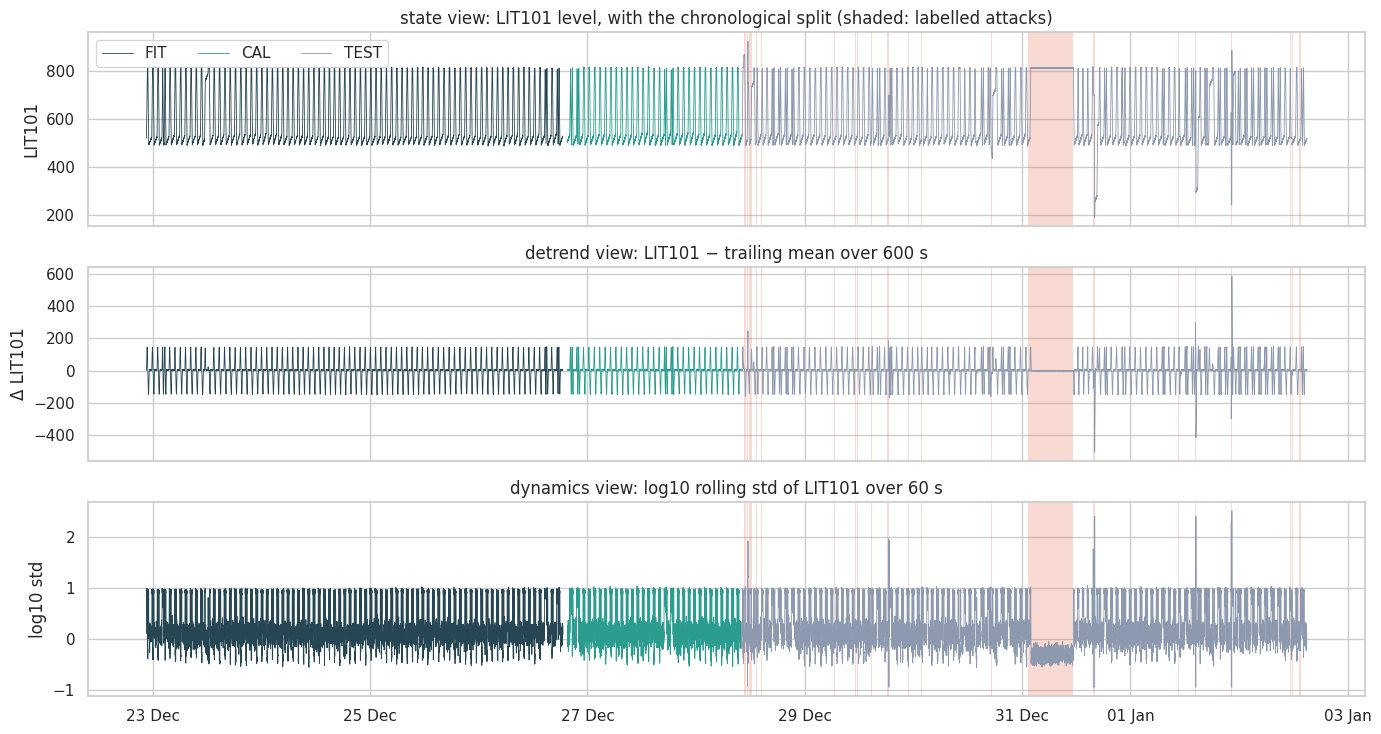

In [9]:
fig, axes = plt.subplots(3, 1, figsize=(14, 7.5), sharex=True)
for name, frame, color in [("FIT", fit_df.iloc[::30], "#264653"), ("CAL", cal_df, "#2a9d8f"), ("TEST", test_df, "#8d99ae")]:
    axes[0].plot(frame["timestamp"], frame["LIT101"], lw=0.6, color=color, label=name)
    axes[1].plot(frame["timestamp"], frame[f"LIT101_dt{W}"], lw=0.6, color=color)
    axes[2].plot(frame["timestamp"], frame[f"LIT101_sd{WS}"], lw=0.6, color=color)
for ax in axes:
    shade_attacks(ax, segments)
axes[0].set(title="state view: LIT101 level, with the chronological split (shaded: labelled attacks)", ylabel="LIT101")
axes[1].set(title=f"detrend view: LIT101 − trailing mean over {W} s", ylabel="Δ LIT101")
axes[2].set(title=f"dynamics view: log10 rolling std of LIT101 over {WS} s", ylabel="log10 std")
axes[0].legend(loc="upper left", ncol=3)
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.tight_layout()
save_fig(fig, "split_and_views")
plt.show()

### **3.1 Drift per feature and view**

Two descriptive measures, neither used to select features: the KS statistic between FIT and the normal TEST rows, and the fraction of TEST rows outside the FIT range.

In [10]:
test_normal_rows = test_df.loc[test_df["is_attack"] == 0]
drift = pd.DataFrame([
    {"feature": f, "view": v,
     "ks_fit_vs_cal": stats.ks_2samp(fit_df[f].iloc[::10], cal_df[f]).statistic,
     "ks_fit_vs_test_normal": stats.ks_2samp(fit_df[f].iloc[::10], test_normal_rows[f]).statistic,
     "test_outside_fit_range": ((test_df[f] < fit_df[f].min()) | (test_df[f] > fit_df[f].max())).mean()}
    for v, feats in VIEW_FEATURES.items() for f in feats
])
drift.to_csv(RUN_DIR / "drift_per_feature.csv", index=False)
display(drift.groupby("view")[["ks_fit_vs_cal", "ks_fit_vs_test_normal", "test_outside_fit_range"]].agg(["mean", "max"]).round(3))
for v, feats in VIEW_FEATURES.items():
    outside = np.any([(test_df[f] < fit_df[f].min()) | (test_df[f] > fit_df[f].max()) for f in feats], axis=0).mean()
    print(f"{v:9s}: TEST rows with ≥1 feature outside the FIT range: {outside:.1%}")

ks_fit_vs_cal        ks_fit_vs_test_normal         \
                  mean    max                  mean    max   
view                                                         
detrend          0.051  0.187                 0.048  0.221   
dynamics         0.105  0.393                 0.140  0.614   
state            0.233  0.785                 0.220  0.776   

         test_outside_fit_range         
                           mean    max  
view                                    
detrend                   0.008  0.013  
dynamics                  0.015  0.076  
state                     0.033  0.124

state    : TEST rows with ≥1 feature outside the FIT range: 21.7%
detrend  : TEST rows with ≥1 feature outside the FIT range: 4.0%
dynamics : TEST rows with ≥1 feature outside the FIT range: 9.8%


## **4. Teacher contexts and distillation rows**

As in v2: each seed draws a **time-stratified** context of `context_size` FIT rows, one random row per consecutive time bin. The same row indices are used for every view, so all teachers see the same moments in time. Distillation rows are FIT rows every `distil_stride` seconds, **excluding every context row**.

In [11]:
def time_stratified_context(n_rows, size, seed):
    rng = np.random.default_rng(seed)
    bins = np.array_split(np.arange(n_rows), size)
    return np.array([rng.choice(b) for b in bins if len(b)])


context_indices = {s: time_stratified_context(len(fit_df), TEACHER_CONFIG["context_size"], s)
                   for s in TEACHER_CONFIG["teacher_seeds"]}
used_in_context = np.unique(np.concatenate(list(context_indices.values())))
distil_idx = np.setdiff1d(np.arange(0, len(fit_df), TEACHER_CONFIG["distil_stride"]), used_in_context)
if len(distil_idx) > TEACHER_CONFIG["distil_max_rows"]:
    distil_idx = distil_idx[np.linspace(0, len(distil_idx) - 1, TEACHER_CONFIG["distil_max_rows"]).round().astype(int)]
distil_df = fit_df.iloc[distil_idx].reset_index(drop=True)
assert not np.isin(distil_idx, used_in_context).any()

# Per-view FIT-only scalers (TabPFN, GMM and autoencoder inputs).
view_scalers = {v: StandardScaler().fit(fit_df[f].to_numpy(np.float32)) for v, f in VIEW_FEATURES.items()}


def scaled(view, frame):
    return view_scalers[view].transform(frame[VIEW_FEATURES[view]].to_numpy(np.float32)).astype(np.float32)


print("Context sizes:", {s: len(i) for s, i in context_indices.items()})
print(f"Rows to score per (view, seed): distil={len(distil_df):,}, cal={len(cal_df):,}, test={len(test_df):,}")

Context sizes: {42: 5000, 43: 5000, 44: 5000}
Rows to score per (view, seed): distil=20,000, cal=13,842, test=44,992


### **4.1 Synthetic corruptions for distillation (change 4)**

Each window takes a random stretch of FIT, corrupts the **raw** signals, and recomputes all view features with the same causal code. Rows are sampled every 10 s. A lookback of max(600, 60) s before the window keeps the rolling features exact.

| kind | corruption | mimics |
|---|---|---|
| `stuck` | one sensor frozen at its value at window start | sensor spoofing / replay |
| `offset` | one sensor + k·IQR (k ∈ [2, 6], random sign) | biased reading |
| `ramp` | one sensor drifting linearly to ± k·IQR | slow manipulation |
| `stage_hold` | **all** sensors of one process stage frozen | a held process: the v2 blind spot |
| `actuator_flip` | one actuator forced to another state seen in FIT, sensors unchanged | command injection without physical effect |

Synthetic rows carry **no labels**. They are scored by the teachers (Part B), and the teacher score is the surrogate's target. They are used **only for surrogate training**: never as TabPFN context, never for thresholds, never in evaluation.

In [12]:
%%time
def sensor_scale(s):
    q75, q25 = np.percentile(fit_df[s], [75, 25])
    return (q75 - q25) if q75 > q25 else float(fit_df[s].std())


STAGES = sorted({re.search(r"(\d)\d\d$", s).group(1) for s in SENSORS_USED})
assert np.all(np.diff(fit_pos) == 1), "synthetic windows assume a contiguous FIT block"
lookback = max(W, WS) + 10
synth_df = pd.DataFrame()
if SYNTH_CONFIG["enabled"]:
    rng = np.random.default_rng(SYNTH_CONFIG["seed"])
    raw_cols = SENSORS_USED + ACTUATORS_USED
    frames = []
    for w in range(SYNTH_CONFIG["n_windows"]):
        kind = SYNTH_CONFIG["kinds"][w % len(SYNTH_CONFIG["kinds"])]
        if kind == "actuator_flip" and not ACTUATORS_USED:
            kind = "stuck"
        dur = int(rng.integers(SYNTH_CONFIG["duration_s"][0], SYNTH_CONFIG["duration_s"][1] + 1))
        start = int(rng.integers(fit_pos[0] + lookback, fit_pos[-1] - dur))
        block = stream.iloc[start - lookback:start + dur][raw_cols].astype(np.float64).reset_index(drop=True)
        a, b = lookback, lookback + dur - 1                      # inclusive label range of corrupted rows
        k = rng.uniform(*SYNTH_CONFIG["offset_iqr"]) * rng.choice([-1.0, 1.0])
        if kind == "stuck":
            target = str(rng.choice(SENSORS_USED)); block.loc[a:b, target] = block.at[a, target]
        elif kind == "offset":
            target = str(rng.choice(SENSORS_USED)); block.loc[a:b, target] += k * sensor_scale(target)
        elif kind == "ramp":
            target = str(rng.choice(SENSORS_USED)); block.loc[a:b, target] += np.linspace(0, k * sensor_scale(target), dur)
        elif kind == "stage_hold":
            target = f"stage {rng.choice(STAGES)}"
            cols = [s for s in SENSORS_USED if re.search(r"(\d)\d\d$", s).group(1) == target[-1]]
            block.loc[a:b, cols] = block.loc[a, cols].to_numpy()
        else:
            target = str(rng.choice(ACTUATORS_USED))
            options = [v for v in sorted(fit_df[target].unique()) if v != block.at[a, target]]
            block.loc[a:b, target] = float(rng.choice(options))
        feats = build_features(block).iloc[a:b + 1:SYNTH_CONFIG["row_stride"]].reset_index(drop=True)
        feats["kind"], feats["window_id"], feats["target"] = kind, w, target
        feats["offset_s"] = np.arange(len(feats)) * SYNTH_CONFIG["row_stride"]
        frames.append(feats)
    synth_df = pd.concat(frames, ignore_index=True)
    display(synth_df.groupby("kind").agg(windows=("window_id", "nunique"), rows=("window_id", "size")))
print(f"Synthetic rows: {len(synth_df):,}")

,windows,rows
kind,,
actuator_flip,32,3785
offset,32,3500
ramp,32,3191
stage_hold,32,3631
stuck,32,3771


Synthetic rows: 17,878
CPU times: user 842 ms, sys: 7.66 ms, total: 850 ms
Wall time: 850 ms


## **Part B — TabPFN density teachers, one per view**

For each view and seed, `TabPFNUnsupervisedModel` is fitted on that seed's context. The chain-rule log-density is then computed for the distillation, CAL, TEST and synthetic rows.

- **Score** = −log-density, calibrated per member to a robust z-score against its own CAL scores: (s − median_CAL) / IQR_CAL.
- **View teacher** = mean over seeds. **Primary teacher `teacher_fused`** = mean of the three view teachers. `teacher_fused_max` is the "any view alarms" variant.
- Feature permutations are reseeded before every batch, so all rows scored by one member use the same chain-rule orders.
- **Caching.** Each (view, seed) member is saved in `teacher/<teacher_fp>/members/`, and its synthetic scores in `synthetic/<synth_fp>/`. A rerun loads what exists and only scores what is missing, so an interrupted run resumes where it stopped.

**Estimated cost on the GB10.** v2 measured ≈ 0.32 ms per row per feature per member at 2 permutations. Here the views have 28 + 16 + 16 features, there are 4 permutations, and each member scores ≈ 95k rows. That gives **≈ 65 min per seed and ≈ 3.3 h for 3 seeds**. `n_permutations: 2` halves it. Each finished member is saved, so the run can be split across sessions.

In [13]:
class DensityCompatibleTabPFNRegressor(TabPFNRegressor):
    # Align full-output logits with the density criterion's bin boundaries.

    def predict(self, X, **kwargs):
        prediction = super().predict(X, **kwargs)
        if kwargs.get("output_type") == "full":
            # TabPFN can return float32 logits with float64 borders, which makes
            # BarDistribution fail inside the extension; align dtype and device.
            borders = prediction["criterion"].borders
            prediction = dict(prediction)
            prediction["logits"] = torch.as_tensor(prediction["logits"]).to(
                dtype=borders.dtype, device=borders.device
            )
        return prediction


def finite_anomaly_score(log_density):
    values = np.asarray(log_density, dtype=np.float64)
    finite = values[np.isfinite(values)]
    if finite.size == 0:
        return np.zeros_like(values)
    clean = np.nan_to_num(values, nan=finite.min(), neginf=finite.min(), posinf=finite.max())
    return -clean


def score_in_batches(model, X, batch_size, n_permutations, permutation_seed):
    chunks = []
    for start in range(0, len(X), batch_size):
        random.seed(permutation_seed)          # same chain-rule orders for every batch
        result = model.outliers(
            torch.as_tensor(X[start:start + batch_size], dtype=torch.float32),
            n_permutations=n_permutations,
        )
        chunks.append(result.detach().cpu().numpy() if torch.is_tensor(result) else np.asarray(result))
    return finite_anomaly_score(np.concatenate(chunks))


def make_teacher(seed):
    kw = dict(n_estimators=TEACHER_CONFIG["n_estimators"], device=DEVICE, random_state=seed,
              memory_saving_mode="auto", show_progress_bar=False)
    return TabPFNUnsupervisedModel(tabpfn_clf=TabPFNClassifier(**kw), tabpfn_reg=DensityCompatibleTabPFNRegressor(**kw))

In [14]:
%%time
MAIN_SPLITS = {"distil": distil_df, "cal": cal_df, "test": test_df}
teacher_members = {}          # (view, seed) -> {split: scores, f"sec_{split}": seconds}
tabpfn_checkpoint = None

for view in VIEW_FEATURES:
    X_pool = scaled(view, fit_df)
    X_splits = {name: scaled(view, frame) for name, frame in MAIN_SPLITS.items()}
    if len(synth_df):
        X_splits["synthetic"] = scaled(view, synth_df)
    for seed in TEACHER_CONFIG["teacher_seeds"]:
        main_path = TEACHER_DIR / "members" / f"{view}_seed_{seed}.npz"
        synth_path = SYNTH_DIR / f"{view}_seed_{seed}.npz"
        member = dict(np.load(main_path)) if main_path.exists() else {}
        if synth_path.exists():
            member.update(dict(np.load(synth_path)))
        missing = [s for s in X_splits if s not in member]
        if not missing:
            print(f"{view:9s} seed {seed}: loaded from cache")
            teacher_members[(view, seed)] = member
            continue

        torch.manual_seed(seed)
        model = make_teacher(seed)
        model.fit(X_pool[context_indices[seed]])
        for split in missing:
            t0 = time.time()
            member[split] = score_in_batches(model, X_splits[split], TEACHER_CONFIG["score_batch_size"],
                                             TEACHER_CONFIG["n_permutations"], permutation_seed=seed)
            member[f"sec_{split}"] = np.array(time.time() - t0)
            print(f"{view:9s} seed {seed}: scored {split:9s} ({len(X_splits[split]):,} rows) in {float(member[f'sec_{split}']):.0f}s")
        main_keys = [k for k in member if k.replace("sec_", "") in MAIN_SPLITS]
        np.savez(main_path, **{k: member[k] for k in main_keys})
        if "synthetic" in member:
            np.savez(synth_path, synthetic=member["synthetic"], sec_synthetic=member["sec_synthetic"])
        teacher_members[(view, seed)] = member

        if tabpfn_checkpoint is None:
            configs = getattr(getattr(model, "tabpfn_reg", None), "configs_", None) or []
            tabpfn_checkpoint = getattr(configs[0], "name", None) if configs else None
        del model
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

if tabpfn_checkpoint:
    record = json.loads(teacher_config_path.read_text())
    record["tabpfn_checkpoint"] = tabpfn_checkpoint
    teacher_config_path.write_text(json.dumps(record, indent=2))
print("TabPFN checkpoint:", json.loads(teacher_config_path.read_text()).get("tabpfn_checkpoint"))

state     seed 42: scored distil    (20,000 rows) in 375s
state     seed 42: scored cal       (13,842 rows) in 288s
state     seed 42: scored test      (44,992 rows) in 830s
state     seed 42: scored synthetic (17,878 rows) in 363s
state     seed 43: scored distil    (20,000 rows) in 372s
state     seed 43: scored cal       (13,842 rows) in 286s
state     seed 43: scored test      (44,992 rows) in 827s
state     seed 43: scored synthetic (17,878 rows) in 361s
state     seed 44: scored distil    (20,000 rows) in 372s
state     seed 44: scored cal       (13,842 rows) in 285s
state     seed 44: scored test      (44,992 rows) in 822s
state     seed 44: scored synthetic (17,878 rows) in 361s
detrend   seed 42: scored distil    (20,000 rows) in 197s
detrend   seed 42: scored cal       (13,842 rows) in 152s
detrend   seed 42: scored test      (44,992 rows) in 438s
detrend   seed 42: scored synthetic (17,878 rows) in 195s
detrend   seed 43: scored distil    (20,000 rows) in 198s
detrend   seed

### **B1. Calibrate, fuse and save the teacher scores (the hand-off to Part C)**

| File | Rows | Contents |
|---|---|---|
| `teacher/<fp>/teacher_distil.parquet` | normal FIT rows, no labels | timestamp, all view features, `teacher_<view>`, `teacher_fused`, `teacher_fused_max`, per-seed columns |
| `teacher/<fp>/teacher_cal.parquet` | later normal rows, no labels | same |
| `teacher/<fp>/teacher_test.parquet` | attack period | same + `is_attack`, `attack_id` |
| `synthetic/<fp>/teacher_synthetic.parquet` | corrupted FIT windows, no labels | same + `kind`, `window_id`, `target`, `offset_s` |

Each parquet file also has a `.csv.gz` copy.

In [15]:
seeds = TEACHER_CONFIG["teacher_seeds"]
views = list(VIEW_FEATURES)
score_splits = ["distil", "cal", "test"] + (["synthetic"] if len(synth_df) else [])
member_z = {
    (v, s, split): robust_z(teacher_members[(v, s)][split], teacher_members[(v, s)]["cal"])
    for v in views for s in seeds for split in score_splits
}


def teacher_frame(frame, split, extra_cols):
    out = frame[(["timestamp"] if "timestamp" in frame else []) + ALL_FEATURES + extra_cols].copy()
    per_view = {v: np.mean([member_z[(v, s, split)] for s in seeds], axis=0) for v in views}
    for v in views:
        out[f"teacher_{v}"] = per_view[v]
        for s in seeds:
            out[f"teacher_{v}_seed_{s}"] = member_z[(v, s, split)]
    stacked = np.column_stack([per_view[v] for v in views])
    out["teacher_fused"] = stacked.mean(axis=1)
    out["teacher_fused_max"] = stacked.max(axis=1)
    out.attrs = {}
    return out


teacher_files = {"distil": teacher_frame(distil_df, "distil", []),
                 "cal": teacher_frame(cal_df, "cal", []),
                 "test": teacher_frame(test_df, "test", ["is_attack", "attack_id"])}
for split, frame in teacher_files.items():
    frame.to_parquet(TEACHER_DIR / f"teacher_{split}.parquet", index=False)
    frame.to_csv(TEACHER_DIR / f"teacher_{split}.csv.gz", index=False)
if len(synth_df):
    teacher_files["synthetic"] = teacher_frame(synth_df, "synthetic", ["kind", "window_id", "target", "offset_s"])
    teacher_files["synthetic"].to_parquet(SYNTH_DIR / "teacher_synthetic.parquet", index=False)
    teacher_files["synthetic"].to_csv(SYNTH_DIR / "teacher_synthetic.csv.gz", index=False)
segments.to_csv(TEACHER_DIR / "attack_segments.csv", index=False)
(TEACHER_DIR / "features.json").write_text(json.dumps({"views": VIEW_FEATURES, "all": ALL_FEATURES}))

main_rows = len(distil_df) + len(cal_df) + len(test_df)
teacher_cost = pd.DataFrame([
    {"view": v, "seed": s, "n_features": len(VIEW_FEATURES[v]),
     "main_seconds": sum(float(teacher_members[(v, s)].get(f"sec_{k}", np.nan)) for k in MAIN_SPLITS),
     "rows_scored": main_rows} for v in views for s in seeds
])
teacher_cost["ms_per_row"] = 1000 * teacher_cost["main_seconds"] / teacher_cost["rows_scored"]
teacher_cost.to_csv(TEACHER_DIR / "teacher_cost.csv", index=False)

print("Saved teacher scores to", TEACHER_DIR.resolve())
display(teacher_cost.round(2))

Saved teacher scores to /home/jaume/_DEVELOPMENT/_projects/tabular-IDS/results/SWaT_A1A2-full-pipeline-v3/teacher/fe81f1e75c


,view,seed,n_features,main_seconds,rows_scored,ms_per_row
0,state,42,28,1493.11,78834,18.94
1,state,43,28,1485.43,78834,18.84
2,state,44,28,1479.19,78834,18.76
3,detrend,42,16,787.43,78834,9.99
4,detrend,43,16,790.82,78834,10.03
5,detrend,44,16,792.16,78834,10.05
6,dynamics,42,16,792.21,78834,10.05
7,dynamics,43,16,792.39,78834,10.05
8,dynamics,44,16,790.87,78834,10.03


### **B2. Teacher results at the CAL-calibrated threshold, and what each view sees**

,threshold,roc_auc,average_precision,precision,recall,f1,test_fpr,accuracy,recall_onset,recall_sustained
teacher,,,,,,,,,,
teacher_state,0.6409,0.7981,0.7025,0.9341,0.6167,0.7429,0.0060,0.9481,0.1050,0.8197
teacher_detrend,2.4175,0.7347,0.2475,0.2015,0.2286,0.2142,0.1253,0.7961,0.6304,0.0692
teacher_dynamics,2.0469,0.8955,0.7929,0.7542,0.7288,0.7413,0.0329,0.9382,0.3921,0.8623
teacher_fused,1.0038,0.9124,0.7266,0.5187,0.8299,0.6384,0.1065,0.8857,0.6800,0.8894
teacher_fused_max,2.5203,0.9088,0.6902,0.4786,0.8034,0.5998,0.1211,0.8697,0.6381,0.8690


,mean,std,min,max
view,,,,
detrend,0.7324,0.0383,0.6882,0.7552
dynamics,0.8951,0.0014,0.8935,0.8963
state,0.8004,0.0269,0.7790,0.8307


figure saved: output-figures/teacher_roc_daily_v3.png


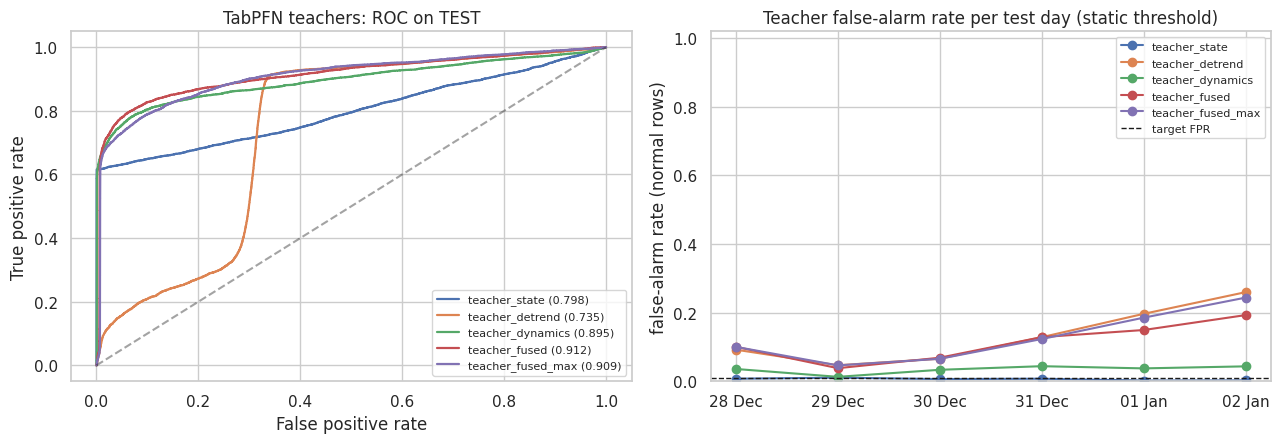

In [16]:
y_test = test_df["is_attack"].to_numpy().astype(int)
tt, tc = teacher_files["test"], teacher_files["cal"]
teacher_variants = [f"teacher_{v}" for v in views] + ["teacher_fused", "teacher_fused_max"]

phase = np.full(len(tt), "normal", dtype=object)
for seg in segments.itertuples(index=False):
    inside = ((tt["timestamp"] >= seg.start) & (tt["timestamp"] <= seg.end)).to_numpy()
    since = (tt["timestamp"] - seg.start).dt.total_seconds().to_numpy()
    phase[inside] = np.where(since[inside] < EVAL_CONFIG["onset_s"], "onset", "sustained")

rows = []
for col in teacher_variants:
    thr = threshold_from_calibration(tc[col], EVAL_CONFIG["target_fpr"])
    pred = tt[col].to_numpy() >= thr
    rows.append({"teacher": col, "threshold": thr, **point_metrics(y_test, tt[col], thr),
                 "recall_onset": pred[phase == "onset"].mean(), "recall_sustained": pred[phase == "sustained"].mean()})
display(pd.DataFrame(rows).set_index("teacher").round(4))

seed_table = pd.DataFrame([{"view": v, "seed": s, "roc_auc": roc_auc_score(y_test, tt[f"teacher_{v}_seed_{s}"])}
                           for v in views for s in seeds])
display(seed_table.groupby("view")["roc_auc"].agg(["mean", "std", "min", "max"]).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for col in teacher_variants:
    f, t_, _ = roc_curve(y_test, tt[col])
    axes[0].plot(f, t_, lw=1.6, label=f"{col} ({roc_auc_score(y_test, tt[col]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="TabPFN teachers: ROC on TEST")
axes[0].legend(fontsize=8)
for col in teacher_variants:
    thr = threshold_from_calibration(tc[col], EVAL_CONFIG["target_fpr"])
    daily = daily_false_alarm_rate(tt["timestamp"], y_test, tt[col] >= thr)
    axes[1].plot(pd.to_datetime(daily.index), daily.values, marker="o", label=col)
axes[1].axhline(EVAL_CONFIG["target_fpr"], color="k", ls="--", lw=1, label="target FPR")
axes[1].set(ylabel="false-alarm rate (normal rows)", title="Teacher false-alarm rate per test day (static threshold)", ylim=(0, 1.02))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[1].legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "teacher_roc_daily")
plt.show()

figure saved: output-figures/teacher_synthetic_sensitivity_v3.png


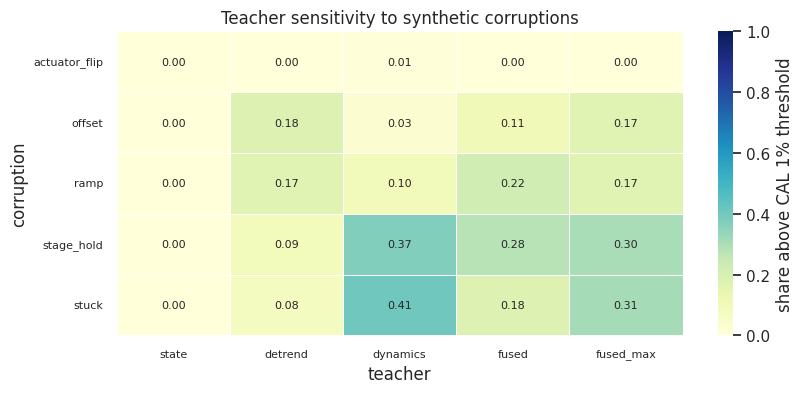

In [17]:
# Does each teacher view react to each synthetic corruption? (share of synthetic rows above that view's CAL threshold)
if "synthetic" in teacher_files:
    ts_ = teacher_files["synthetic"]
    sens = pd.DataFrame({
        col.replace("teacher_", ""): ts_.groupby("kind")[col].apply(
            lambda s, c=col: float((s >= threshold_from_calibration(tc[c], EVAL_CONFIG["target_fpr"])).mean()))
        for col in teacher_variants
    })
    sens.to_csv(SYNTH_DIR / "teacher_synthetic_sensitivity.csv")
    fig, ax = plt.subplots(figsize=(1.1 * sens.shape[1] + 3, 0.5 * sens.shape[0] + 1.6))
    sns.heatmap(sens, annot=True, fmt=".2f", annot_kws={"size": 8}, cmap="YlGnBu", vmin=0, vmax=1, linewidths=0.4,
                cbar_kws={"label": "share above CAL 1% threshold"}, ax=ax)
    ax.set(xlabel="teacher", ylabel="corruption", title="Teacher sensitivity to synthetic corruptions")
    ax.tick_params(labelsize=8)
    plt.tight_layout()
    save_fig(fig, "teacher_synthetic_sensitivity")
    plt.show()

## **Part C — Surrogates distilled from the saved teacher scores (changes 3 and 4)**

**This part is self-contained:** restart the kernel, run §0, and start here. It reads only `teacher/<teacher_fp>/` and `synthetic/<synth_fp>/`.

| | normal-only distillation | normal + synthetic corruptions |
|---|---|---|
| CatBoost (constant leaves) | `catboost|normal` | `catboost|synthetic` |
| LightGBM `linear_tree=True` | `lightgbm_linear|normal` | **`lightgbm_linear|synthetic`** (primary) |

- **Target:** the rank (empirical CDF over the training rows) of the **fused** teacher.
- **Inputs:** all view features (state + detrend + dynamics), the same information the three teachers see.
- **Early stopping:** the last 15% of the normal distillation rows in time, plus 20% of the synthetic windows (whole windows, so no window leaks between train and eval).
- **Threshold:** the same rule as everywhere else, the CAL quantile of the surrogate's own predictions.

In [18]:
# ---- Standalone entry point: restart kernel -> run §0 -> run from here ----
teacher_record = json.loads((TEACHER_DIR / "teacher_config.json").read_text())
assert teacher_record["teacher_fingerprint"] == TEACHER_FINGERPRINT
SURROGATE_FEATURES = json.loads((TEACHER_DIR / "features.json").read_text())["all"]

distil_t = pd.read_parquet(TEACHER_DIR / "teacher_distil.parquet")
cal_t = pd.read_parquet(TEACHER_DIR / "teacher_cal.parquet")
test_t = pd.read_parquet(TEACHER_DIR / "teacher_test.parquet")
synth_path = SYNTH_DIR / "teacher_synthetic.parquet"
synth_t = pd.read_parquet(synth_path) if synth_path.exists() else pd.DataFrame()
assert "is_attack" not in distil_t.columns and "is_attack" not in cal_t.columns   # label-free training data

target_col = SURROGATE_CONFIG["distil_target"]
n_eval = int(SURROGATE_CONFIG["eval_fraction"] * len(distil_t))
normal_train, normal_eval = distil_t.iloc[:-n_eval], distil_t.iloc[-n_eval:]
TRAIN_SETS = {"normal": (normal_train, normal_eval)}
synth_eval = pd.DataFrame()
if len(synth_t) and "synthetic" in SURROGATE_CONFIG["train_sets"]:
    n_windows = synth_t["window_id"].nunique()
    eval_windows = np.random.default_rng(SYNTH_CONFIG["seed"]).choice(
        synth_t["window_id"].unique(), int(SYNTH_CONFIG["eval_fraction"] * n_windows), replace=False)
    is_eval = synth_t["window_id"].isin(eval_windows)
    TRAIN_SETS["synthetic"] = (pd.concat([normal_train, synth_t[~is_eval]], ignore_index=True),
                               pd.concat([normal_eval, synth_t[is_eval]], ignore_index=True))
    synth_eval = synth_t[is_eval]
TRAIN_SETS = {k: v for k, v in TRAIN_SETS.items() if k in SURROGATE_CONFIG["train_sets"]}


def rank_transform(reference):
    sorted_ref = np.sort(np.asarray(reference))
    return lambda values: np.searchsorted(sorted_ref, np.asarray(values), side="right") / len(sorted_ref)


print(f"Teacher {TEACHER_FINGERPRINT} (TabPFN {teacher_record.get('tabpfn_checkpoint')}) | target: {target_col} ({SURROGATE_CONFIG['target']})")
for k, (tr, ev) in TRAIN_SETS.items():
    print(f"  train set {k:9s}: train={len(tr):,} eval={len(ev):,}")
print(f"  cal={len(cal_t):,} test={len(test_t):,} features={len(SURROGATE_FEATURES)}")

Teacher fe81f1e75c (TabPFN TabPFN-v3.5) | target: teacher_fused (rank)
  train set normal   : train=17,000 eval=3,000
  train set synthetic: train=31,295 eval=6,583
  cal=13,842 test=44,992 features=60


In [19]:
%%time
def fit_catboost(X_tr, y_tr, X_ev, y_ev):
    c = SURROGATE_CONFIG["catboost"]
    model = CatBoostRegressor(loss_function=c["loss_function"], iterations=c["iterations"],
                              learning_rate=c["learning_rate"], depth=c["depth"], l2_leaf_reg=c["l2_leaf_reg"],
                              random_seed=c["random_seed"], od_type="Iter", od_wait=c["early_stopping_rounds"],
                              use_best_model=True, thread_count=-1, verbose=0)
    model.fit(Pool(X_tr, y_tr), eval_set=Pool(X_ev, y_ev))
    return model, model.get_best_iteration()


def fit_lightgbm(X_tr, y_tr, X_ev, y_ev):
    c = dict(SURROGATE_CONFIG["lightgbm"])
    rounds = c.pop("early_stopping_rounds")
    model = lgb.LGBMRegressor(**c, n_jobs=-1, verbosity=-1)
    model.fit(X_tr, y_tr, eval_set=[(X_ev, y_ev)], callbacks=[lgb.early_stopping(rounds, verbose=False)])
    return model, model.best_iteration_


FITTERS = {"catboost": fit_catboost, "lightgbm_linear": fit_lightgbm}
surrogates, surrogate_scores, surrogate_rows = {}, {}, []
for model_name, fitter in FITTERS.items():
    for set_name, (train_part, eval_part) in TRAIN_SETS.items():
        name = f"{model_name}|{set_name}"
        to_target = (rank_transform(train_part[target_col]) if SURROGATE_CONFIG["target"] == "rank" else (lambda v: np.asarray(v)))
        t0 = time.time()
        model, best_iter = fitter(train_part[SURROGATE_FEATURES], to_target(train_part[target_col]),
                                  eval_part[SURROGATE_FEATURES], to_target(eval_part[target_col]))
        fit_seconds = time.time() - t0
        surrogates[name] = model
        frames = [("normal_eval", normal_eval), ("cal", cal_t), ("test", test_t)]
        if len(synth_eval):
            frames.append(("synth_eval", synth_eval))
        surrogate_scores[name] = {split: model.predict(frame[SURROGATE_FEATURES]) for split, frame in frames}
        stem = name.replace("|", "__")
        if model_name == "catboost":
            model.save_model(SURROGATE_DIR / f"{stem}.cbm")
        else:
            model.booster_.save_model(str(SURROGATE_DIR / f"{stem}.txt"))
        for split in ["cal", "test"]:
            pd.DataFrame({"score": surrogate_scores[name][split]}).to_parquet(SURROGATE_DIR / f"{stem}_{split}.parquet", index=False)
        surrogate_rows.append({"surrogate": name, "best_iteration": best_iter, "fit_seconds": fit_seconds})
        print(f"{name:28s} best_iter={best_iter:5d}  fit={fit_seconds:5.1f}s")

(SURROGATE_DIR / "surrogate_config.json").write_text(json.dumps({
    "teacher_fingerprint": TEACHER_FINGERPRINT, "synth_fingerprint": SYNTH_FINGERPRINT,
    "surrogate_config": SURROGATE_CONFIG, "features": SURROGATE_FEATURES,
    "written": datetime.now().isoformat(timespec="seconds")}, indent=2))

catboost|normal              best_iter= 3996  fit= 20.6s
catboost|synthetic           best_iter= 3994  fit= 23.7s
lightgbm_linear|normal       best_iter= 2466  fit=228.1s
lightgbm_linear|synthetic    best_iter= 2859  fit=271.6s
CPU times: user 1h 7min 44s, sys: 4min 38s, total: 1h 12min 22s
Wall time: 9min 9s


1964

### **C1. Fidelity and detection: does synthetic data fix the v2 inversion?**

- **Fidelity** is the Spearman correlation with the teacher score. It needs no labels, so TEST fidelity is legitimate.
- **`spearman_test_attack`** uses labels only to pick the rows and shows whether the surrogate follows the teacher *inside attacks*. In v2 it fell to about 0.6, and the surrogate's attack scores were lower than its normal scores.

surrogate,catboost|normal,catboost|synthetic,lightgbm_linear|normal,lightgbm_linear|synthetic
spearman_normal_eval,0.9318,0.8942,0.9220,0.9052
spearman_synth_eval,0.5571,0.8023,0.6643,0.7388
spearman_cal,0.9361,0.9090,0.9199,0.8990
spearman_test,0.7196,0.7000,0.7910,0.3607
spearman_test_attack,0.3797,0.2263,0.6258,-0.3844
median_attack_minus_normal,0.0879,0.0292,0.9310,-0.4603
roc_auc,0.6434,0.6023,0.8871,0.3138
average_precision,0.1815,0.1867,0.5873,0.1395
test_fpr,0.0283,0.0385,0.0784,0.0589
recall,0.0604,0.0931,0.7961,0.1355


figure saved: output-figures/surrogate_fidelity_v3.png


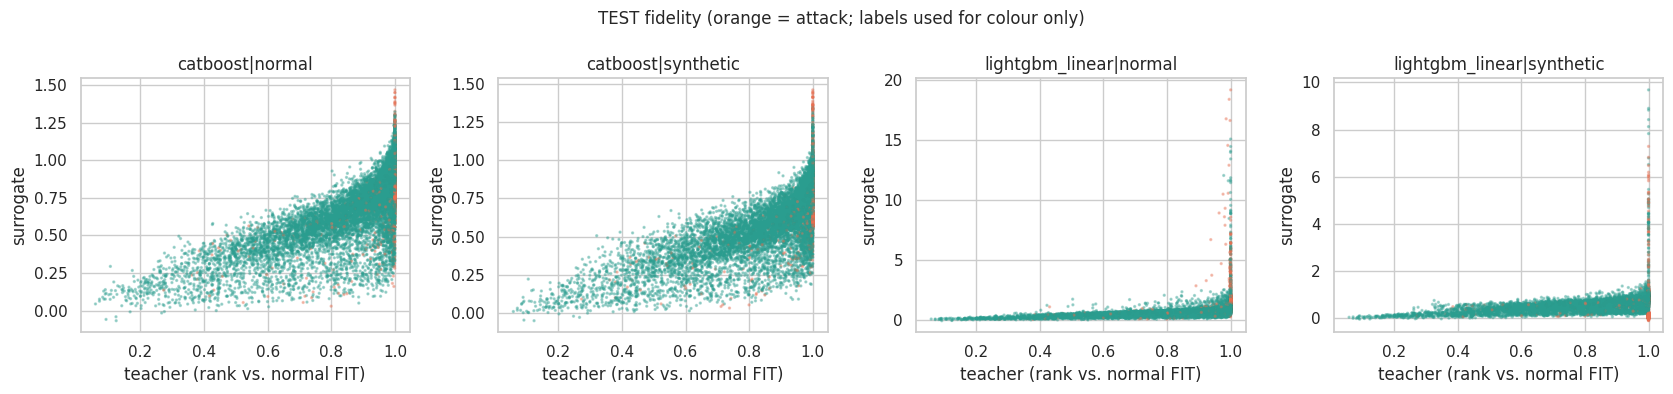

In [20]:
y_test_c = test_t["is_attack"].to_numpy().astype(int)
att = y_test_c == 1
rows = []
for name, sc in surrogate_scores.items():
    thr = threshold_from_calibration(sc["cal"], EVAL_CONFIG["target_fpr"])
    point = point_metrics(y_test_c, sc["test"], thr)
    rows.append({
        "surrogate": name,
        "spearman_normal_eval": stats.spearmanr(sc["normal_eval"], normal_eval[target_col]).statistic,
        "spearman_synth_eval": (stats.spearmanr(sc["synth_eval"], synth_eval[target_col]).statistic if "synth_eval" in sc else np.nan),
        "spearman_cal": stats.spearmanr(sc["cal"], cal_t[target_col]).statistic,
        "spearman_test": stats.spearmanr(sc["test"], test_t[target_col]).statistic,
        "spearman_test_attack": stats.spearmanr(sc["test"][att], test_t[target_col][att]).statistic,
        "median_attack_minus_normal": np.median(sc["test"][att]) - np.median(sc["test"][~att]),
        "roc_auc": point["roc_auc"], "average_precision": point["average_precision"],
        "test_fpr": point["test_fpr"], "recall": point["recall"], "f1": point["f1"],
    })
surrogate_table = pd.DataFrame(rows).merge(pd.DataFrame(surrogate_rows), on="surrogate")
surrogate_table.to_csv(RUN_DIR / "results_surrogate_ablation.csv", index=False)
display(surrogate_table.set_index("surrogate").T.round(4))

fig, axes = plt.subplots(1, len(surrogate_scores), figsize=(4.2 * len(surrogate_scores), 4), squeeze=False)
sub = np.random.default_rng(0).choice(len(test_t), min(12000, len(test_t)), replace=False)
teacher_rank = rank_transform(normal_train[target_col])(test_t[target_col])
for ax, (name, sc) in zip(axes[0], surrogate_scores.items()):
    ax.scatter(teacher_rank[sub], sc["test"][sub], s=2, alpha=0.35, c=np.where(att[sub], "#e76f51", "#2a9d8f"))
    ax.set(title=name, xlabel="teacher (rank vs. normal FIT)", ylabel="surrogate")
fig.suptitle("TEST fidelity (orange = attack; labels used for colour only)", fontsize=12)
plt.tight_layout()
save_fig(fig, "surrogate_fidelity")
plt.show()

figure saved: output-figures/surrogate_importance_v3.png


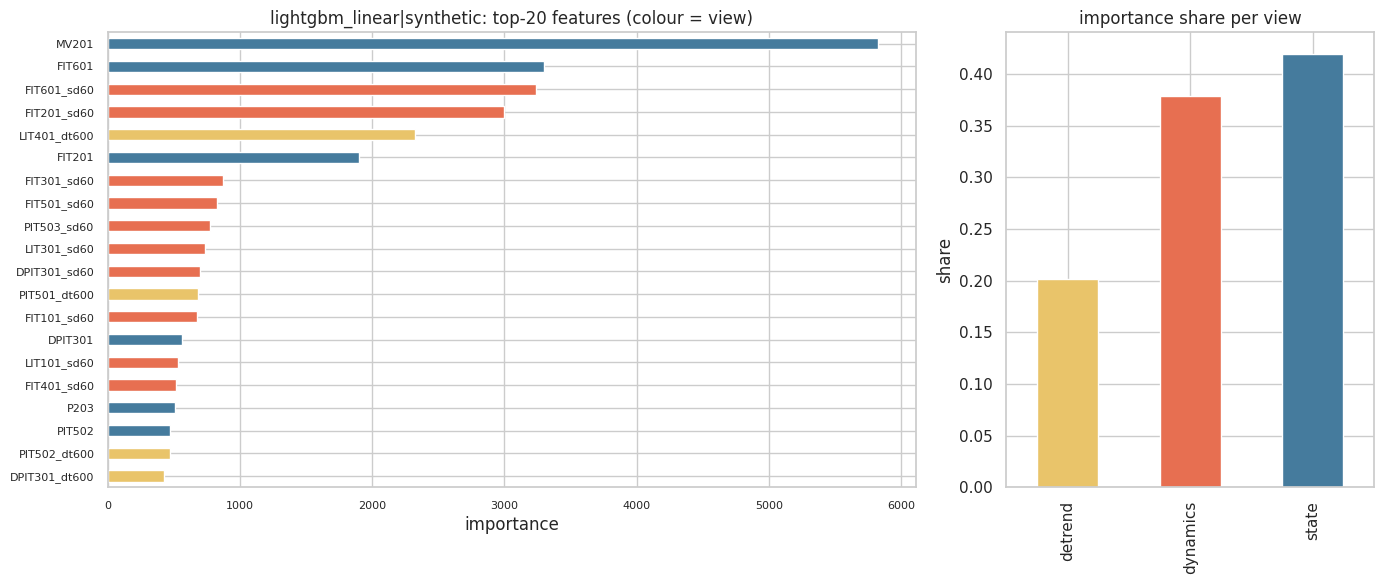

In [21]:
primary_name = SURROGATE_CONFIG["primary"]
model = surrogates[primary_name]
imp = model.get_feature_importance() if primary_name.startswith("catboost") else model.booster_.feature_importance("gain")
imp = pd.Series(imp, index=SURROGATE_FEATURES)
view_of = {f: v for v, feats in json.loads((TEACHER_DIR / "features.json").read_text())["views"].items() for f in feats}
fig, axes = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [2.2, 1]})
top = imp.sort_values().tail(20)
palette = {"state": "#457b9d", "detrend": "#e9c46a", "dynamics": "#e76f51"}
top.plot.barh(ax=axes[0], color=[palette.get(view_of[f], "#888") for f in top.index])
axes[0].set(title=f"{primary_name}: top-20 features (colour = view)", xlabel="importance")
axes[0].tick_params(labelsize=8)
(imp.groupby(imp.index.map(view_of)).sum() / imp.sum()).plot.bar(ax=axes[1], color=[palette[v] for v in sorted(set(view_of.values()))])
axes[1].set(title="importance share per view", ylabel="share")
plt.tight_layout()
save_fig(fig, "surrogate_importance")
plt.show()

## **Part D — Baselines: denoising autoencoder and Gaussian mixture (same features, split and threshold rule)**

They need §1–§4 in memory.
- **D1. Autoencoder:** trained on all FIT rows (1 Hz) using all view features. The last 10% of FIT, in time order, is used for early stopping, and the threshold comes from CAL.

In [22]:
def ae_matrix(frame):
    return np.hstack([scaled(v, frame) for v in AE_CONFIG["feature_views"]]).astype(np.float32)


X_ae_all = ae_matrix(fit_df)
n_val = int(AE_CONFIG["val_fraction"] * len(X_ae_all))
X_ae_fit, X_ae_val = X_ae_all[:-n_val], X_ae_all[-n_val:]
X_ae_cal, X_ae_test = ae_matrix(cal_df), ae_matrix(test_df)


class DenoisingAutoencoder(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(input_dim, 64), nn.LayerNorm(64), nn.GELU(),
                                     nn.Linear(64, 32), nn.GELU(), nn.Linear(32, 8))
        self.decoder = nn.Sequential(nn.Linear(8, 32), nn.GELU(), nn.Linear(32, 64), nn.GELU(),
                                     nn.Linear(64, input_dim))

    def forward(self, x):
        return self.decoder(self.encoder(x))


def reconstruction_scores(model, values, batch_size=8192):
    model.eval()
    scores = []
    with torch.no_grad():
        for (batch,) in DataLoader(TensorDataset(torch.from_numpy(values)), batch_size=batch_size):
            batch = batch.to(DEVICE)
            scores.append(torch.mean((model(batch) - batch) ** 2, dim=1).cpu().numpy())
    return np.concatenate(scores)


print("AE fit:", X_ae_fit.shape, "| val:", X_ae_val.shape, "| cal:", X_ae_cal.shape, "| test:", X_ae_test.shape)

AE fit: (298242, 60) | val: (33138, 60) | cal: (13842, 60) | test: (44992, 60)


In [23]:
%%time
torch.manual_seed(AE_CONFIG["seed"])
autoencoder = DenoisingAutoencoder(X_ae_fit.shape[1]).to(DEVICE)
optimizer = torch.optim.AdamW(autoencoder.parameters(), lr=AE_CONFIG["learning_rate"], weight_decay=1e-5)
loss_fn = nn.MSELoss()
fit_loader = DataLoader(TensorDataset(torch.from_numpy(X_ae_fit)), batch_size=AE_CONFIG["batch_size"], shuffle=True)

best_state, best_val, stale = None, np.inf, 0
for epoch in range(1, AE_CONFIG["max_epochs"] + 1):
    autoencoder.train()
    running, seen = 0.0, 0
    for (batch,) in fit_loader:
        batch = batch.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        loss = loss_fn(autoencoder(batch + AE_CONFIG["noise_std"] * torch.randn_like(batch)), batch)
        loss.backward()
        optimizer.step()
        running += loss.item() * len(batch); seen += len(batch)
    val_loss = float(reconstruction_scores(autoencoder, X_ae_val).mean())
    print(f"epoch={epoch:02d} train_mse={running / seen:.6f} val_mse={val_loss:.6f}")
    if val_loss < best_val - 1e-6:
        best_val, best_state, stale = val_loss, copy.deepcopy(autoencoder.state_dict()), 0
    else:
        stale += 1
        if stale >= AE_CONFIG["patience"]:
            print(f"Early stopping at epoch {epoch}")
            break
autoencoder.load_state_dict(best_state)

ae_scores = {"cal": reconstruction_scores(autoencoder, X_ae_cal), "test": reconstruction_scores(autoencoder, X_ae_test)}
for split in ["cal", "test"]:
    pd.DataFrame({"score": ae_scores[split]}).to_parquet(RUN_DIR / f"ae_{split}.parquet", index=False)
threshold_d = threshold_from_calibration(ae_scores["cal"], EVAL_CONFIG["target_fpr"])
for k, v in point_metrics(y_test, ae_scores["test"], threshold_d).items():
    print(f"  {k:18s} {v:.4f}")

epoch=01 train_mse=0.483290 val_mse=0.335621
epoch=02 train_mse=0.224849 val_mse=0.267921
epoch=03 train_mse=0.191182 val_mse=0.245487
epoch=04 train_mse=0.177313 val_mse=0.237599
epoch=05 train_mse=0.168553 val_mse=0.230911
epoch=06 train_mse=0.158679 val_mse=0.230751
epoch=07 train_mse=0.144850 val_mse=0.227768
epoch=08 train_mse=0.136994 val_mse=0.219342
epoch=09 train_mse=0.133406 val_mse=0.211265
epoch=10 train_mse=0.130355 val_mse=0.205626
epoch=11 train_mse=0.126459 val_mse=0.198044
epoch=12 train_mse=0.122815 val_mse=0.193960
epoch=13 train_mse=0.119782 val_mse=0.189662
epoch=14 train_mse=0.116948 val_mse=0.187045
epoch=15 train_mse=0.114516 val_mse=0.182722
epoch=16 train_mse=0.112495 val_mse=0.179959
epoch=17 train_mse=0.110789 val_mse=0.179338
epoch=18 train_mse=0.109423 val_mse=0.177374
epoch=19 train_mse=0.108047 val_mse=0.178510
epoch=20 train_mse=0.106985 val_mse=0.176349
epoch=21 train_mse=0.105972 val_mse=0.176296
epoch=22 train_mse=0.105093 val_mse=0.177948
epoch=23 t

### **D2. Gaussian mixture density baseline: one per view, fused like the teacher**

This is the same model as in `SWaT_A1A2-density-pipeline.ipynb`: a full-covariance GMM on a FIT subsample, with *k* chosen by BIC, scored as −log p. It is fitted on **exactly the features each TabPFN teacher sees** (same scaler, same FIT rows, no labels). The views are then **fused exactly like the teacher** (robust z against CAL, mean / max), so **TabPFN fused vs. GMM fused** isolates what the foundation-model density adds over a classical one.

In [24]:
%%time
gmm_raw, gmm_rows = {}, []
for view in GMM_CONFIG["views"]:
    if view not in VIEW_FEATURES:
        continue
    X_fit = scaled(view, fit_df)[::GMM_CONFIG["fit_stride"]]
    best = None
    for k in GMM_CONFIG["components_grid"]:
        gmm = GaussianMixture(k, covariance_type=GMM_CONFIG["covariance"], reg_covar=GMM_CONFIG["reg_covar"],
                              random_state=GMM_CONFIG["seed"]).fit(X_fit)
        bic = gmm.bic(X_fit)
        if best is None or bic < best[0]:
            best = (bic, k, gmm)
    _, k, gmm = best
    X_test_view = scaled(view, test_df)
    t0 = time.perf_counter()
    test_scores = -gmm.score_samples(X_test_view)
    ms_per_row = 1000 * (time.perf_counter() - t0) / len(X_test_view)
    gmm_raw[view] = {"cal": -gmm.score_samples(scaled(view, cal_df)), "test": test_scores}
    thr = threshold_from_calibration(gmm_raw[view]["cal"], EVAL_CONFIG["target_fpr"])
    point = point_metrics(y_test, gmm_raw[view]["test"], thr)
    gmm_rows.append({"view": view, "k": k, "ms_per_row_batched": ms_per_row, **point})
    print(f"GMM {view:9s} k={k:2d}  AUC={point['roc_auc']:.4f}  test FPR={point['test_fpr']:.3f}  recall={point['recall']:.3f}")

gmm_z = {v: {s: robust_z(gmm_raw[v][s], gmm_raw[v]["cal"]) for s in ["cal", "test"]} for v in gmm_raw}
gmm_out = {**{v: gmm_z[v] for v in gmm_z},
           "fused": {s: np.mean([gmm_z[v][s] for v in gmm_z], axis=0) for s in ["cal", "test"]},
           "fused_max": {s: np.max([gmm_z[v][s] for v in gmm_z], axis=0) for s in ["cal", "test"]}}
for name, sc in gmm_out.items():
    for split in ["cal", "test"]:
        pd.DataFrame({"score": sc[split]}).to_parquet(RUN_DIR / f"gmm_{name}_{split}.parquet", index=False)
pd.DataFrame(gmm_rows).to_csv(RUN_DIR / "gmm_summary.csv", index=False)
display(pd.DataFrame(gmm_rows).set_index("view").round(4))

GMM state     k=32  AUC=0.9246  test FPR=0.319  recall=0.905
GMM detrend   k=32  AUC=0.8693  test FPR=0.146  recall=0.881
GMM dynamics  k=32  AUC=0.9049  test FPR=0.042  recall=0.718


,k,ms_per_row_batched,roc_auc,average_precision,precision,recall,f1,test_fpr,accuracy
view,,,,,,,,,
state,32,0.0057,0.9246,0.8341,0.2817,0.9045,0.4297,0.3190,0.7081
detrend,32,0.0011,0.8693,0.4219,0.4550,0.8815,0.6002,0.1461,0.8573
dynamics,32,0.0025,0.9049,0.7915,0.7019,0.7184,0.7101,0.0422,0.9287


CPU times: user 11min 53s, sys: 0 ns, total: 11min 53s
Wall time: 43.3 s


## **E. Evaluation (Plan §1): every table rebuilt from the saved files**

This section reloads only the saved score files. Methods:

| family | methods |
|---|---|
| TabPFN teacher | **fused (primary)**, fused-max, state, detrend, dynamics |
| GMM baseline | fused, fused-max, state, detrend, dynamics |
| Surrogates | CatBoost / LightGBM-linear × normal-only / +synthetic |
| Autoencoder | all view features |

Two thresholds are reported for every method:
- **static**: the CAL quantile, as in v1/v2;
- **adaptive**: the score normalised by its trailing-24 h median/IQR (label-free), then thresholded at the CAL quantile of the normalised score.

Plots use the core set (TabPFN fused, GMM fused, the surrogates trained with synthetic data, the autoencoder); tables include every method.

In [25]:
cfg = json.loads((RUN_DIR / "config.json").read_text())
ecfg = cfg["eval_config"]
target_fpr = ecfg["target_fpr"]
stride_s = cfg["teacher_config"]["test_stride"]
ev_test = pd.read_parquet(TEACHER_DIR / "teacher_test.parquet")
ev_cal = pd.read_parquet(TEACHER_DIR / "teacher_cal.parquet")
ev_segments = pd.read_csv(TEACHER_DIR / "attack_segments.csv", parse_dates=["start", "end"])
y_eval = ev_test["is_attack"].to_numpy().astype(int)
ts_eval = ev_test["timestamp"]
view_names = list(json.loads((TEACHER_DIR / "features.json").read_text())["views"])


def load_scores(directory, stem):
    return (pd.read_parquet(directory / f"{stem}_test.parquet")["score"].to_numpy(),
            pd.read_parquet(directory / f"{stem}_cal.parquet")["score"].to_numpy())


SURROGATE_LABEL = {"catboost": "CatBoost", "lightgbm_linear": "LGBM-linear"}
METHODS = {"TabPFN fused": (ev_test["teacher_fused"].to_numpy(), ev_cal["teacher_fused"].to_numpy()),
           "TabPFN fused-max": (ev_test["teacher_fused_max"].to_numpy(), ev_cal["teacher_fused_max"].to_numpy())}
for v in view_names:
    METHODS[f"TabPFN {v}"] = (ev_test[f"teacher_{v}"].to_numpy(), ev_cal[f"teacher_{v}"].to_numpy())
for g in ["fused", "fused_max"] + view_names:
    if (RUN_DIR / f"gmm_{g}_test.parquet").exists():
        METHODS[f"GMM {g.replace('_', '-')}"] = load_scores(RUN_DIR, f"gmm_{g}")
for model_name in SURROGATE_LABEL:
    for set_name in cfg["surrogate_config"]["train_sets"]:
        stem = f"{model_name}__{set_name}"
        if (SURROGATE_DIR / f"{stem}_test.parquet").exists():
            label = f"{SURROGATE_LABEL[model_name]} {'+synth' if set_name == 'synthetic' else 'normal-only'}"
            METHODS[label] = load_scores(SURROGATE_DIR, stem)
METHODS["Autoencoder"] = load_scores(RUN_DIR, "ae")

p_model, p_set = cfg["surrogate_config"]["primary"].split("|")
PRIMARY_SURROGATE = f"{SURROGATE_LABEL[p_model]} {'+synth' if p_set == 'synthetic' else 'normal-only'}"
CORE = [m for m in ["TabPFN fused", "GMM fused", PRIMARY_SURROGATE, "CatBoost +synth", "Autoencoder"] if m in METHODS]
names = list(METHODS)
score_matrix = {m: METHODS[m][0] for m in names}
THRESHOLDS = {m: threshold_from_calibration(cal, target_fpr) for m, (_, cal) in METHODS.items()}

ADAPTIVE = {}
for m, (test_s, cal_s) in METHODS.items():
    z_cal, z_test = adaptive_normalise(cal_s, test_s, stride_s, ecfg)
    ADAPTIVE[m] = (z_test, threshold_from_calibration(z_cal, target_fpr))

phase_eval = np.full(len(ev_test), "normal", dtype=object)
for seg in ev_segments.itertuples(index=False):
    inside = ((ts_eval >= seg.start) & (ts_eval <= seg.end)).to_numpy()
    since = (ts_eval - seg.start).dt.total_seconds().to_numpy()
    phase_eval[inside] = np.where(since[inside] < ecfg["onset_s"], "onset", "sustained")

method_colors = dict(zip(names, sns.color_palette("tab20", len(names))))
print(f"Run {cfg['run_id']} | run {cfg['run_fingerprint']} | teacher {cfg['teacher_fingerprint']} | surrogates {cfg['surrogate_fingerprint']}")
print(f"TEST rows: {len(y_eval):,} ({y_eval.sum():,} attack) | events: {len(ev_segments)} | target FPR {target_fpr}")
print(f"Methods ({len(names)}): {names}")
print(f"Core set for plots: {CORE}")

Run SWaT_A1A2-full-pipeline-v3 | run bf936a2bb2 | teacher fe81f1e75c | surrogates f487a86a7d
TEST rows: 44,992 (5,468 attack) | events: 35 | target FPR 0.01
Methods (15): ['TabPFN fused', 'TabPFN fused-max', 'TabPFN state', 'TabPFN detrend', 'TabPFN dynamics', 'GMM fused', 'GMM fused-max', 'GMM state', 'GMM detrend', 'GMM dynamics', 'CatBoost normal-only', 'CatBoost +synth', 'LGBM-linear normal-only', 'LGBM-linear +synth', 'Autoencoder']
Core set for plots: ['TabPFN fused', 'GMM fused', 'LGBM-linear +synth', 'CatBoost +synth', 'Autoencoder']


### **E1. Point-wise and event-wise results: static vs. adaptive threshold**

`recall_onset` / `recall_sustained` split attack rows into the first 10 min of each attack and the rest. This split is the v2 diagnosis.

In [26]:
rows, per_event_tables = [], {}
for method in names:
    for mode, (scores, thr) in {"static": (score_matrix[method], THRESHOLDS[method]),
                                "adaptive": ADAPTIVE[method]}.items():
        pred = scores >= thr
        point = point_metrics(y_eval, np.nan_to_num(scores, nan=-np.inf), thr)
        event, per_event = event_metrics(ts_eval, y_eval, pred, ev_segments)
        per_event_tables[(method, mode)] = per_event
        rows.append({"method": method, "threshold_mode": mode, "threshold": thr, **point, **event,
                     "recall_onset": pred[phase_eval == "onset"].mean(),
                     "recall_sustained": pred[phase_eval == "sustained"].mean()})
main_results = pd.DataFrame(rows)
main_results.insert(0, "run_fingerprint", cfg["run_fingerprint"])
main_results.to_csv(RUN_DIR / "results_main.csv", index=False)
show_cols = ["roc_auc", "average_precision", "test_fpr", "recall", "recall_onset", "recall_sustained", "precision",
             "f1", "attacks_detected", "false_alarm_episodes", "composite_f1", "median_ttd_s"]
for mode in ["static", "adaptive"]:
    print(f"--- {mode} threshold ---")
    display(main_results[main_results["threshold_mode"] == mode].set_index("method")[show_cols].round(4))

--- static threshold ---


,roc_auc,average_precision,test_fpr,recall,recall_onset,recall_sustained,precision,f1,attacks_detected,false_alarm_episodes,composite_f1,median_ttd_s
method,,,,,,,,,,,,
TabPFN fused,0.9124,0.7266,0.1065,0.8299,0.6800,0.8894,0.5187,0.6384,28,1123,0.6293,5.5
TabPFN fused-max,0.9088,0.6902,0.1211,0.8034,0.6381,0.8690,0.4786,0.5998,26,1053,0.5821,6.5
TabPFN state,0.7981,0.7025,0.0060,0.6167,0.1050,0.8197,0.9341,0.7429,9,194,0.4033,150.0
TabPFN detrend,0.7347,0.2475,0.1253,0.2286,0.6304,0.0692,0.2015,0.2142,24,1002,0.3115,5.5
TabPFN dynamics,0.8955,0.7929,0.0329,0.7288,0.3921,0.8623,0.7542,0.7413,28,533,0.7764,25.5
GMM fused,0.9318,0.8285,0.2654,0.9236,0.7985,0.9732,0.3249,0.4807,30,744,0.4712,5.0
GMM fused-max,0.9309,0.8203,0.2702,0.9148,0.7933,0.9630,0.3190,0.4730,29,890,0.4607,5.0
GMM state,0.9246,0.8341,0.3190,0.9045,0.7888,0.9504,0.2817,0.4297,30,1065,0.4241,5.0
GMM detrend,0.8693,0.4219,0.1461,0.8815,0.6941,0.9558,0.4550,0.6002,25,757,0.5559,6.0


--- adaptive threshold ---


,roc_auc,average_precision,test_fpr,recall,recall_onset,recall_sustained,precision,f1,attacks_detected,false_alarm_episodes,composite_f1,median_ttd_s
method,,,,,,,,,,,,
TabPFN fused,0.9007,0.6568,0.0371,0.6183,0.5171,0.6585,0.6973,0.6554,24,371,0.6914,6.0
TabPFN fused-max,0.8869,0.5729,0.0263,0.4916,0.3554,0.5456,0.7214,0.5847,20,152,0.6377,20.5
TabPFN state,0.7984,0.6883,0.0208,0.6231,0.1269,0.8199,0.8056,0.7027,11,506,0.4522,135.0
TabPFN detrend,0.6872,0.2292,0.0270,0.1282,0.3593,0.0365,0.3960,0.1937,20,169,0.4678,6.5
TabPFN dynamics,0.8832,0.7135,0.0154,0.5521,0.2949,0.6542,0.8319,0.6637,23,237,0.7343,34.0
GMM fused,0.9095,0.7402,0.0510,0.6829,0.6143,0.7101,0.6495,0.6658,26,254,0.6931,5.0
GMM fused-max,0.9089,0.7293,0.0617,0.6869,0.6053,0.7193,0.6062,0.6440,26,298,0.6676,5.0
GMM state,0.9016,0.7528,0.0395,0.6489,0.5357,0.6937,0.6942,0.6708,25,259,0.7041,6.0
GMM detrend,0.8247,0.3493,0.0583,0.2275,0.5679,0.0925,0.3505,0.2759,25,251,0.4703,36.0


#### **Confusion matrices: real vs. predicted (static and adaptive threshold, core methods)**

Rows are the **real** label and columns are the **predicted** label, on TEST rows (1 every 10 s). Each cell shows the count and the share of its real class:
- **Normal → Attack** = the test FPR.
- **Attack → Attack** = the recall.

Titles add attacks detected out of 35 and **false-alarm episodes** (alarm runs that touch no attack row). The table has the counts for every method.

TN     FP    FN    TP  \
method                  threshold_mode                             
TabPFN fused            static          35313   4211   930  4538   
                        adaptive        38056   1468  2087  3381   
TabPFN fused-max        static          34738   4786  1075  4393   
                        adaptive        38486   1038  2780  2688   
TabPFN state            static          39286    238  2096  3372   
                        adaptive        38702    822  2061  3407   
TabPFN detrend          static          34570   4954  4218  1250   
                        adaptive        38455   1069  4767   701   
TabPFN dynamics         static          38225   1299  1483  3985   
                        adaptive        38914    610  2449  3019   
GMM fused               static          29033  10491   418  5050   
                        adaptive        37509   2015  1734  3734   
GMM fused-max           static          28846  10678   466  5002   
                        adaptive        37084   2440  1712  3756   
GMM state               static          26915  12609   522  4946   
                        adaptive        37961   1563  1920  3548   
GMM detrend             static          33751   5773   648  4820   
                        adaptive        37219   2305  4224  1244   
GMM dynamics            static          37856   1668  1540  3928   
                        adaptive        38469   1055  2355  3113   
CatBoost normal-only    static          38407   1117  5138   330   
                        adaptive        38249   1275  5157   311   
CatBoost +synth         static          38002   1522  4959   509   
                        adaptive        37827   1697  4963   505   
LGBM-linear normal-only static          36426   3098  1115  4353   
                        adaptive        37982   1542  2198  3270   
LGBM-linear +synth      static          37197   2327  4727   741   
                        adaptive        38555    969  4884   584   
Autoencoder             static          37405   2119  1222  4246   
                        adaptive        38880    644  2280  3188   

                                        attacks_detected  false_alarm_episodes  
method                  threshold_mode                                          
TabPFN fused            static                        28                  1123  
                        adaptive                      24                   371  
TabPFN fused-max        static                        26                  1053  
                        adaptive                      20                   152  
TabPFN state            static                         9                   194  
                        adaptive                      11                   506  
TabPFN detrend          static                        24                  1002  
                        adaptive                      20                   169  
TabPFN dynamics         static                        28                   533  
                        adaptive                      23                   237  
GMM fused               static                        30                   744  
                        adaptive                      26                   254  
GMM fused-max           static                        29                   890  
                        adaptive                      26                   298  
GMM state               static                        30                  1065  
                        adaptive                      25                   259  
GMM detrend             static                        25                   757  
                        adaptive                      25                   251  
GMM dynamics            static                        27                   497  
                        adaptive                      24                   305  
CatBoost normal-only    static                        19                   644  
   

figure saved: output-figures/confusion_matrices_v3.png


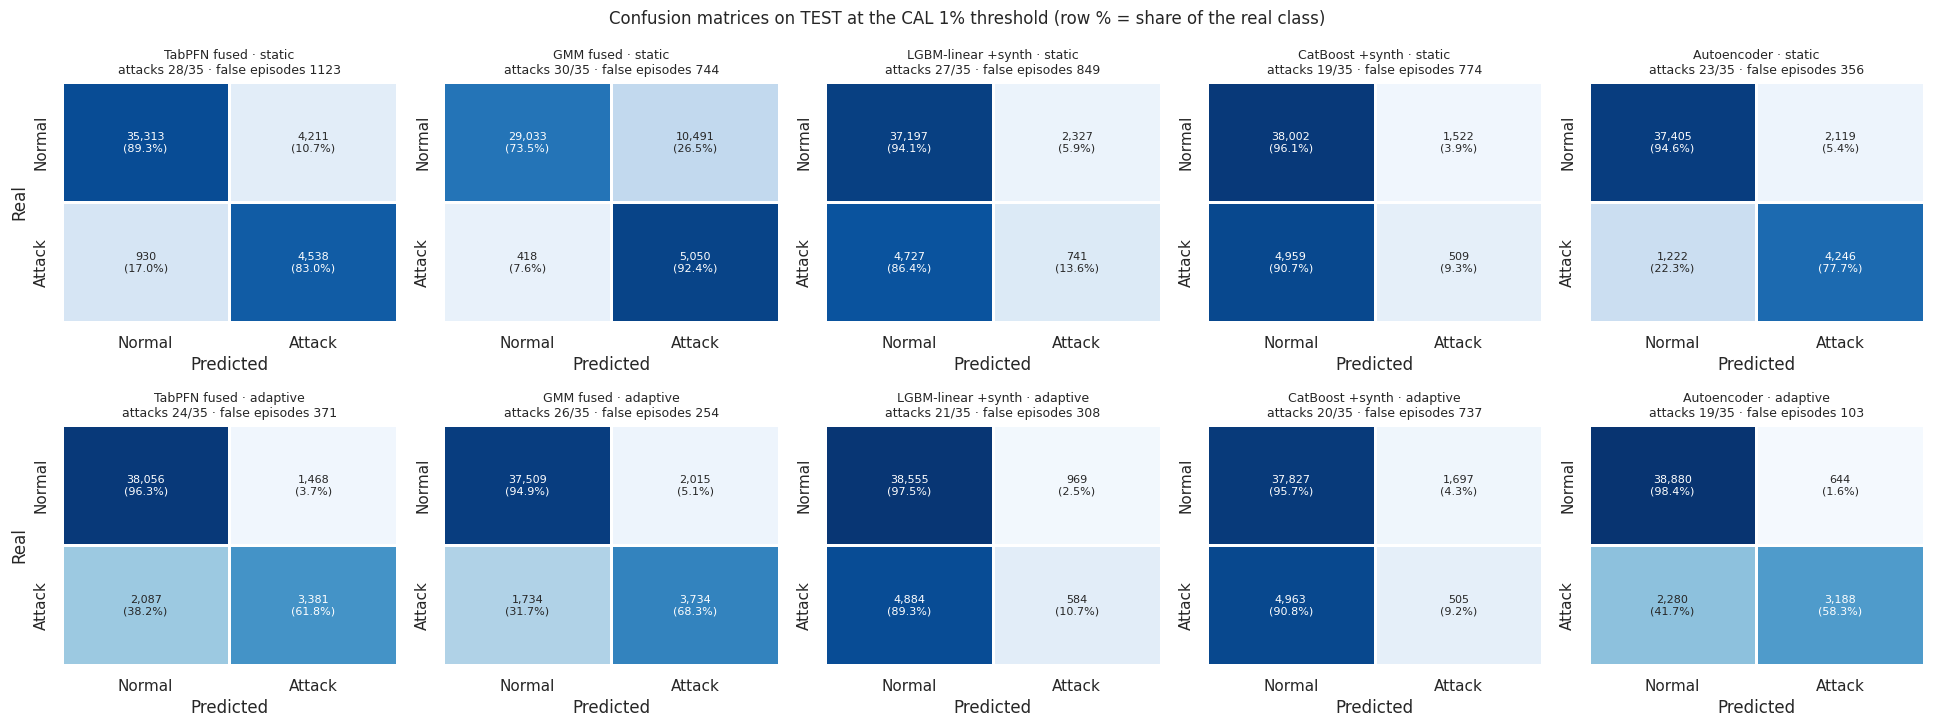

In [27]:
cm_rows = []
for method in names:
    for mode, (scores, thr) in {"static": (score_matrix[method], THRESHOLDS[method]), "adaptive": ADAPTIVE[method]}.items():
        tn, fp, fn, tp = confusion_matrix(y_eval, (scores >= thr).astype(int), labels=[0, 1]).ravel()
        r = main_results[(main_results["method"] == method) & (main_results["threshold_mode"] == mode)].iloc[0]
        cm_rows.append({"method": method, "threshold_mode": mode, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
                        "attacks_detected": int(r["attacks_detected"]), "false_alarm_episodes": int(r["false_alarm_episodes"])})
confusion_table = pd.DataFrame(cm_rows)
confusion_table.to_csv(RUN_DIR / "results_confusion.csv", index=False)
display(confusion_table.set_index(["method", "threshold_mode"]))

fig, axes = plt.subplots(2, len(CORE), figsize=(3.9 * len(CORE), 7.4), squeeze=False)
for row_i, mode in enumerate(["static", "adaptive"]):
    for ax, m in zip(axes[row_i], CORE):
        r = confusion_table[(confusion_table["method"] == m) & (confusion_table["threshold_mode"] == mode)].iloc[0]
        counts = np.array([[r.TN, r.FP], [r.FN, r.TP]])
        share = counts / counts.sum(axis=1, keepdims=True)
        labels = np.array([[f"{c:,}\n({p:.1%})" for c, p in zip(cr, pr)] for cr, pr in zip(counts, share)])
        sns.heatmap(share, annot=labels, fmt="", annot_kws={"size": 8}, cmap="Blues", vmin=0, vmax=1, cbar=False,
                    linewidths=1, xticklabels=["Normal", "Attack"], yticklabels=["Normal", "Attack"], ax=ax)
        ax.set(xlabel="Predicted", ylabel="Real" if ax is axes[row_i][0] else "")
        ax.set_title(f"{m} · {mode}\nattacks {r.attacks_detected}/{len(ev_segments)} · false episodes {r.false_alarm_episodes}", fontsize=9)
fig.suptitle(f"Confusion matrices on TEST at the CAL {target_fpr:.0%} threshold (row % = share of the real class)", fontsize=12)
plt.tight_layout()
save_fig(fig, "confusion_matrices")
plt.show()

### **E2. Several operating points (static threshold)**

Every threshold is taken from CAL. Checking several targets guards against conclusions that only hold at one threshold (Plan §6).

In [28]:
grid_rows = []
for fpr_target in ecfg["fpr_grid"]:
    for method, (scores, cal) in METHODS.items():
        thr = threshold_from_calibration(cal, fpr_target)
        point = point_metrics(y_eval, scores, thr)
        event, _ = event_metrics(ts_eval, y_eval, scores >= thr, ev_segments)
        grid_rows.append({"target_fpr": fpr_target, "method": method, "test_fpr": point["test_fpr"],
                          "precision": point["precision"], "recall": point["recall"], "f1": point["f1"],
                          "attacks_detected": f"{event['attacks_detected']}/{event['attacks_total']}",
                          "composite_f1": event["composite_f1"], "median_ttd_s": event["median_ttd_s"]})
operating_points = pd.DataFrame(grid_rows)
operating_points.to_csv(RUN_DIR / "results_operating_points.csv", index=False)
display(operating_points.pivot(index="method", columns="target_fpr", values=["test_fpr", "recall", "attacks_detected"]).loc[names])

test_fpr                                  recall  \
target_fpr                  0.005     0.010     0.020     0.050     0.005   
method                                                                      
TabPFN fused             0.079977  0.106543   0.14285  0.224319  0.810351   
TabPFN fused-max         0.088048  0.121091  0.160434  0.239449  0.778164   
TabPFN state             0.002555  0.006022  0.013966  0.040861  0.616313   
TabPFN detrend           0.091438  0.125342  0.174653  0.250911  0.203731   
TabPFN dynamics          0.022265  0.032866    0.0504  0.095031  0.702085   
GMM fused                0.207368  0.265434  0.313278  0.414634  0.909839   
GMM fused-max            0.198082  0.270165  0.373444  0.569578   0.88771   
GMM state                0.192921  0.319021  0.404919  0.612312  0.869422   
GMM detrend              0.111552  0.146063  0.188594  0.259184  0.860827   
GMM dynamics             0.022872  0.042202  0.063379  0.121344  0.684528   
CatBoost normal-only      0.01847  0.028261  0.044555  0.092349  0.052487   
CatBoost +synth          0.024036  0.038508  0.061785   0.11803  0.082114   
LGBM-linear normal-only  0.067276  0.078383  0.096321  0.143887  0.792246   
LGBM-linear +synth       0.043847  0.058876   0.08782  0.154893  0.122165   
Autoencoder              0.036965  0.053613  0.087415  0.201574  0.758961   

                                                      attacks_detected         \
target_fpr                  0.010     0.020     0.050            0.005  0.010   
method                                                                          
TabPFN fused              0.82992  0.848391  0.874543            28/35  28/35   
TabPFN fused-max         0.803402  0.832846  0.874726            26/35  26/35   
TabPFN state             0.616679  0.618691  0.628383             8/35   9/35   
TabPFN detrend           0.228603  0.256035  0.309071            24/35  24/35   
TabPFN dynamics          0.728786  0.756035  0.801024            25/35  28/35   
GMM fused                0.923555  0.929407  0.936723            29/35  30/35   
GMM fused-max            0.914777  0.929225  0.964338            29/35  29/35   
GMM state                0.904535  0.923555  0.960132            29/35  30/35   
GMM detrend              0.881492  0.892465  0.903987            25/35  25/35   
GMM dynamics             0.718361   0.75695  0.831748            24/35  27/35   
CatBoost normal-only     0.060351  0.072238  0.099671            15/35  19/35   
CatBoost +synth          0.093087  0.108632  0.146854            18/35  19/35   
LGBM-linear normal-only  0.796086  0.804865  0.822421            22/35  23/35   
LGBM-linear +synth       0.135516  0.153072  0.187454            22/35  27/35   
Autoencoder              0.776518  0.809437  0.872531            23/35  23/35   

                                       
target_fpr               0.020  0.050  
method                                 
TabPFN fused             30/35  31/35  
TabPFN fused-max         28/35  31/35  
TabPFN state             11/35  14/35  
TabPFN detrend           28/35  30/35  
TabPFN dynamics          28/35  29/35  
GMM fused                30/35  32/35  
GMM fused-max            32/35  34/35  
GMM state                32/35  34/35  
GMM detrend              26/35  29/35  
GMM dynamics             29/35  30/35  
CatBoost normal-only     22/35  29/35  
CatBoost +synth          24/35  28/35  
LGBM-linear normal-only  26/35  30/35  
LGBM-linear +synth       30/35  31/35  
Autoencoder              24/35  31/35

### **E3. Uncertainty: block-bootstrap replicates for every method, and seeds**

The circular block bootstrap (1 h blocks) resamples TEST rows with their autocorrelation intact. Every method is scored on the **same** replicate indices, so paired differences (§F3) come directly from these replicates.

In [29]:
%%time
rng = np.random.default_rng(ecfg["bootstrap_seed"])
block = ecfg["bootstrap_block_rows"]
boot = []
for _ in range(ecfg["bootstrap_repeats"]):
    idx = block_bootstrap_indices(len(y_eval), block, rng)
    yb = y_eval[idx]
    if yb.min() == yb.max():
        continue
    rec = {}
    for m in names:
        rec[f"auc|{m}"] = roc_auc_score(yb, score_matrix[m][idx])
        rec[f"ap|{m}"] = average_precision_score(yb, score_matrix[m][idx])
    boot.append(rec)
boot = pd.DataFrame(boot)
boot.to_parquet(RUN_DIR / "bootstrap_replicates.parquet", index=False)

ci_rows = []
for m in names:
    for metric, key, point in [("ROC-AUC", "auc", roc_auc_score(y_eval, score_matrix[m])),
                               ("Average precision", "ap", average_precision_score(y_eval, score_matrix[m]))]:
        lo, hi = np.quantile(boot[f"{key}|{m}"], [0.025, 0.975])
        ci_rows.append({"method": m, "metric": metric, "estimate": point, "ci_low": lo, "ci_high": hi})
ci_table = pd.DataFrame(ci_rows)
ci_table.to_csv(RUN_DIR / "results_bootstrap_ci.csv", index=False)
print(f"Circular block bootstrap: {len(boot)} replicates, block = {block} rows")
display(ci_table.pivot(index="method", columns="metric", values=["estimate", "ci_low", "ci_high"]).loc[names].round(4))

seed_cols = [c for c in ev_test.columns if "_seed_" in c]
seed_table = pd.DataFrame([
    {"view": c.split("_seed_")[0].replace("teacher_", ""), "seed": c.split("_seed_")[1],
     "roc_auc": roc_auc_score(y_eval, ev_test[c]), "average_precision": average_precision_score(y_eval, ev_test[c])}
    for c in seed_cols
])
seed_table.to_csv(RUN_DIR / "results_teacher_seeds.csv", index=False)
display(seed_table.groupby("view")[["roc_auc", "average_precision"]].agg(["mean", "std"]).round(4))

Circular block bootstrap: 1000 replicates, block = 360 rows


estimate                    ci_low          \
metric                  Average precision ROC-AUC Average precision ROC-AUC   
method                                                                        
TabPFN fused                       0.7266  0.9124            0.5751  0.8539   
TabPFN fused-max                   0.6902  0.9088            0.5271  0.8565   
TabPFN state                       0.7025  0.7981            0.5007  0.6818   
TabPFN detrend                     0.2475  0.7347            0.1816  0.6959   
TabPFN dynamics                    0.7929  0.8955            0.6328  0.8241   
GMM fused                          0.8285  0.9318            0.6846  0.8843   
GMM fused-max                      0.8203  0.9309            0.6771  0.8827   
GMM state                          0.8341  0.9246            0.6946  0.8684   
GMM detrend                        0.4219  0.8693            0.3202  0.8276   
GMM dynamics                       0.7915  0.9049            0.6259  0.8402   
CatBoost normal-only               0.1815  0.6434            0.1230  0.5946   
CatBoost +synth                    0.1867  0.6023            0.1349  0.5518   
LGBM-linear normal-only            0.5873  0.8871            0.4279  0.8216   
LGBM-linear +synth                 0.1395  0.3138            0.0952  0.2049   
Autoencoder                        0.7399  0.9176            0.5767  0.8605   

                                  ci_high          
metric                  Average precision ROC-AUC  
method                                             
TabPFN fused                       0.8377  0.9544  
TabPFN fused-max                   0.8166  0.9501  
TabPFN state                       0.8315  0.8854  
TabPFN detrend                     0.3151  0.7758  
TabPFN dynamics                    0.8863  0.9463  
GMM fused                          0.9138  0.9674  
GMM fused-max                      0.9096  0.9665  
GMM state                          0.9195  0.9662  
GMM detrend                        0.5199  0.9036  
GMM dynamics                       0.8863  0.9497  
CatBoost normal-only               0.2416  0.6856  
CatBoost +synth                    0.2430  0.6589  
LGBM-linear normal-only            0.7302  0.9344  
LGBM-linear +synth                 0.2032  0.4721  
Autoencoder                        0.8569  0.9565

roc_auc         average_precision        
            mean     std              mean     std
view                                              
detrend   0.7324  0.0383            0.2477  0.0198
dynamics  0.8951  0.0014            0.7925  0.0028
state     0.8004  0.0269            0.7075  0.0183

CPU times: user 2min 38s, sys: 0 ns, total: 2min 38s
Wall time: 2min 38s


figure saved: output-figures/auc_ap_ci_all_methods_v3.png


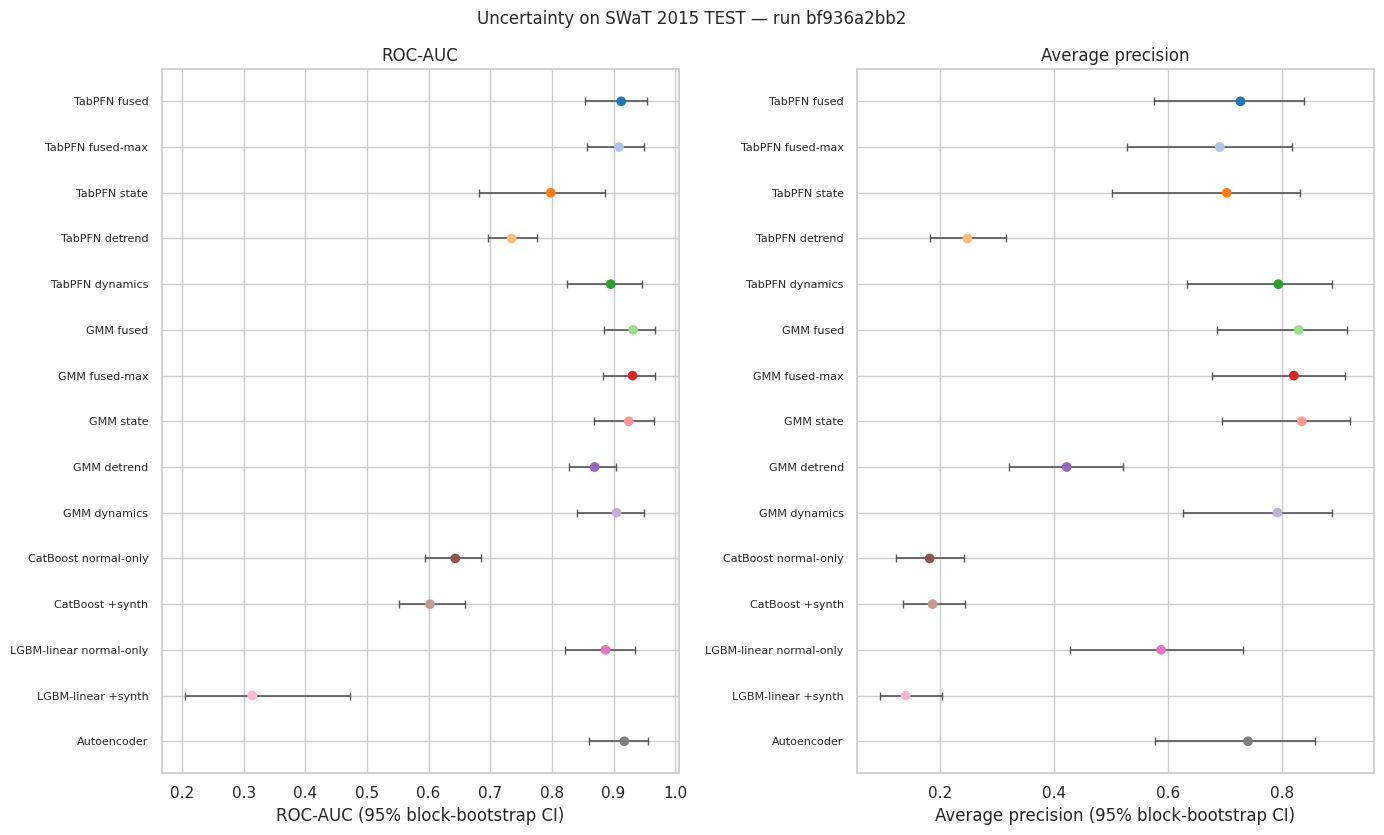

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 0.42 * len(names) + 2.2))
for ax, metric in zip(axes, ["ROC-AUC", "Average precision"]):
    view = ci_table[ci_table["metric"] == metric].set_index("method").loc[names]
    ypos = np.arange(len(view))
    ax.errorbar(view["estimate"], ypos, xerr=[view["estimate"] - view["ci_low"], view["ci_high"] - view["estimate"]],
                fmt="none", ecolor="#555", capsize=3, lw=1.2)
    ax.scatter(view["estimate"], ypos, c=[method_colors[m] for m in names], s=36, zorder=3)
    ax.set(yticks=ypos, xlabel=f"{metric} (95% block-bootstrap CI)", title=metric)
    ax.set_yticklabels(names, fontsize=8)
    ax.invert_yaxis()
fig.suptitle(f"Uncertainty on SWaT 2015 TEST — run {cfg['run_fingerprint']}", fontsize=12)
plt.tight_layout()
save_fig(fig, "auc_ap_ci_all_methods")
plt.show()

### **E4. Per-attack detection (static threshold)**

figure saved: output-figures/per_attack_coverage_v3.png


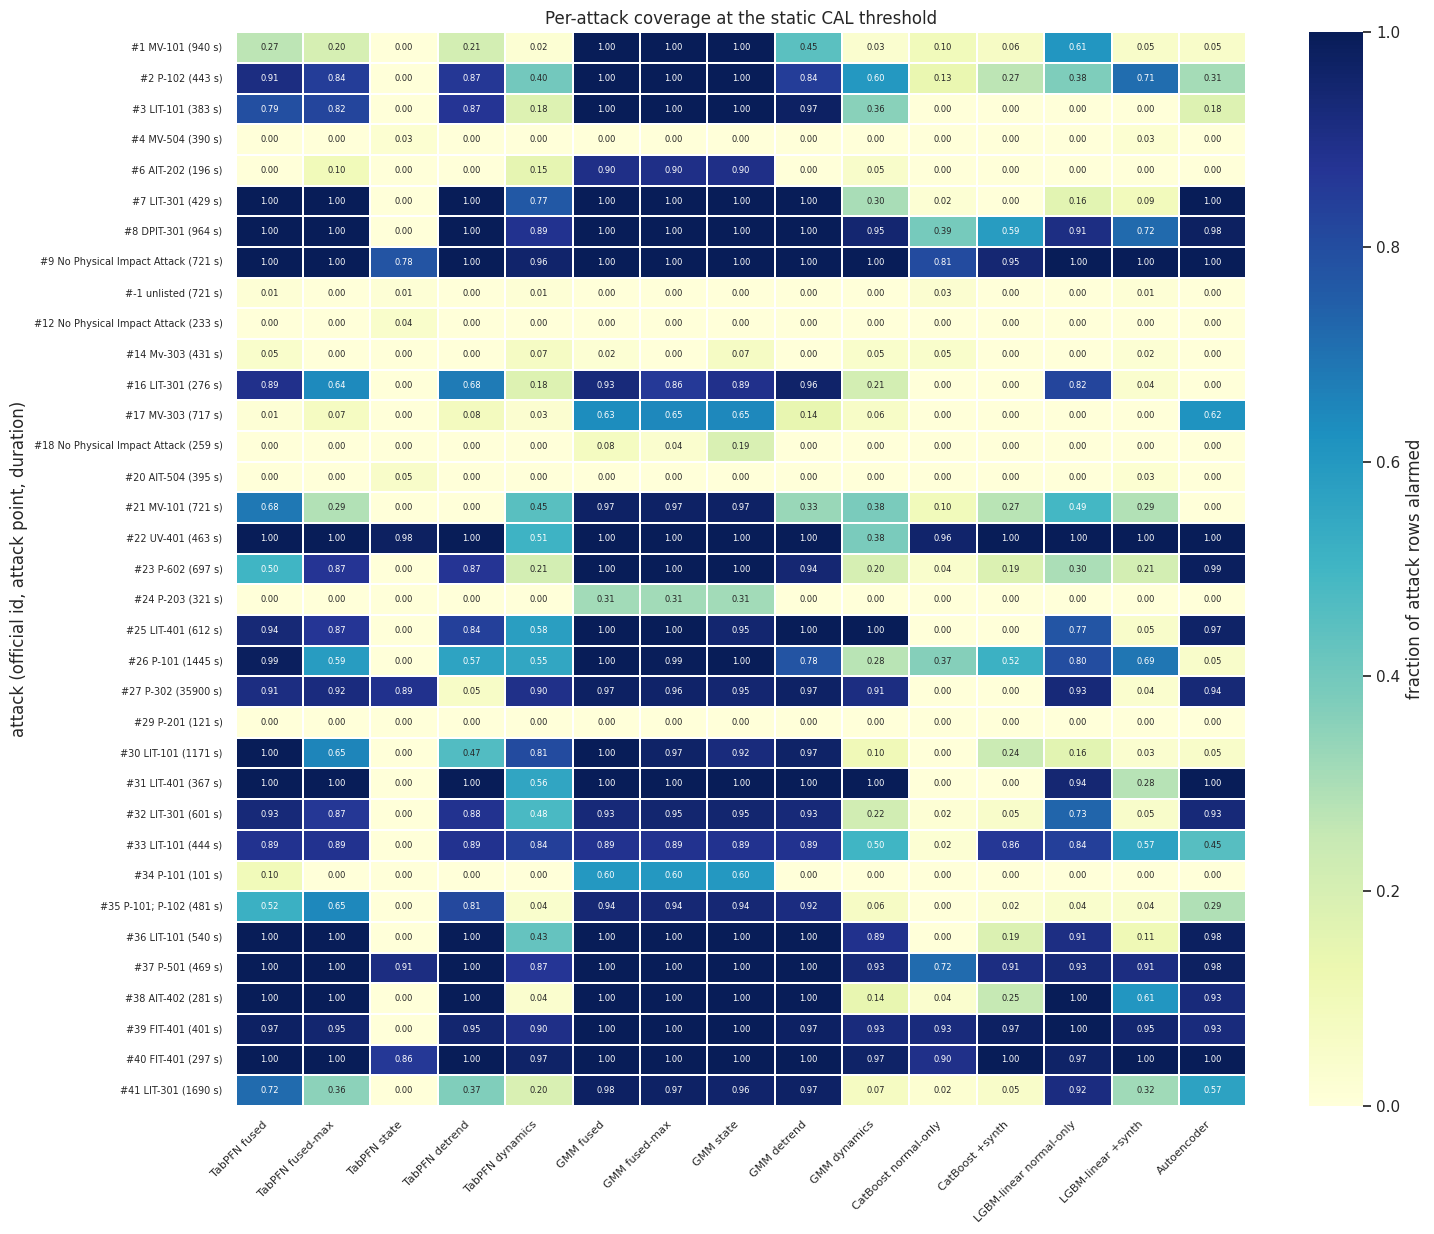

In [31]:
event_view = per_event_tables[(names[0], "static")][["segment", "attack_id", "attack_point", "start", "duration_s"]].copy()
for m in names:
    event_view[f"{m} detected"] = per_event_tables[(m, "static")]["detected"]
    event_view[f"{m} TTD (s)"] = per_event_tables[(m, "static")]["time_to_detect_s"]
event_view.to_csv(RUN_DIR / "results_per_attack.csv", index=False)

heat = pd.DataFrame({m: per_event_tables[(m, "static")]["fraction_alarmed"].to_numpy() for m in names})
heat.index = [f"#{r.attack_id} {r.attack_point} ({int(r.duration_s)} s)" for r in event_view.itertuples()]
fig, ax = plt.subplots(figsize=(0.75 * len(names) + 4, 0.3 * len(heat) + 2))
sns.heatmap(heat, annot=True, fmt=".2f", annot_kws={"size": 6}, cmap="YlGnBu", vmin=0, vmax=1, linewidths=0.3,
            cbar_kws={"label": "fraction of attack rows alarmed"}, ax=ax)
ax.set(xlabel="", ylabel="attack (official id, attack point, duration)", title="Per-attack coverage at the static CAL threshold")
ax.tick_params(axis="x", rotation=45, labelsize=8)
ax.tick_params(axis="y", labelsize=7)
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout()
save_fig(fig, "per_attack_coverage")
plt.show()

### **E5. Curves, score distributions and the score timeline (core methods)**

figure saved: output-figures/roc_pr_core_v3.png


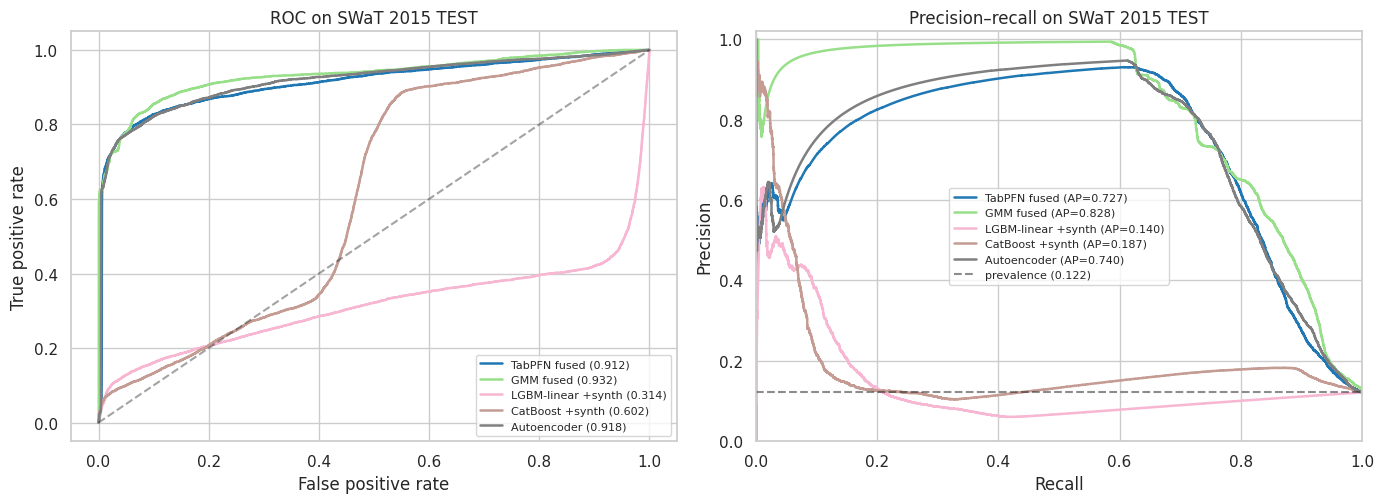

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for m in CORE:
    s = score_matrix[m]
    f, t_, _ = roc_curve(y_eval, s)
    axes[0].plot(f, t_, lw=1.8, color=method_colors[m], label=f"{m} ({roc_auc_score(y_eval, s):.3f})")
    p, r, _ = precision_recall_curve(y_eval, s)
    axes[1].plot(r, p, lw=1.8, color=method_colors[m], label=f"{m} (AP={average_precision_score(y_eval, s):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC on SWaT 2015 TEST")
axes[1].axhline(y_eval.mean(), color="k", ls="--", alpha=0.5, label=f"prevalence ({y_eval.mean():.3f})")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision–recall on SWaT 2015 TEST", xlim=(0, 1), ylim=(0, 1.02))
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "roc_pr_core")
plt.show()

figure saved: output-figures/score_distributions_v3.png


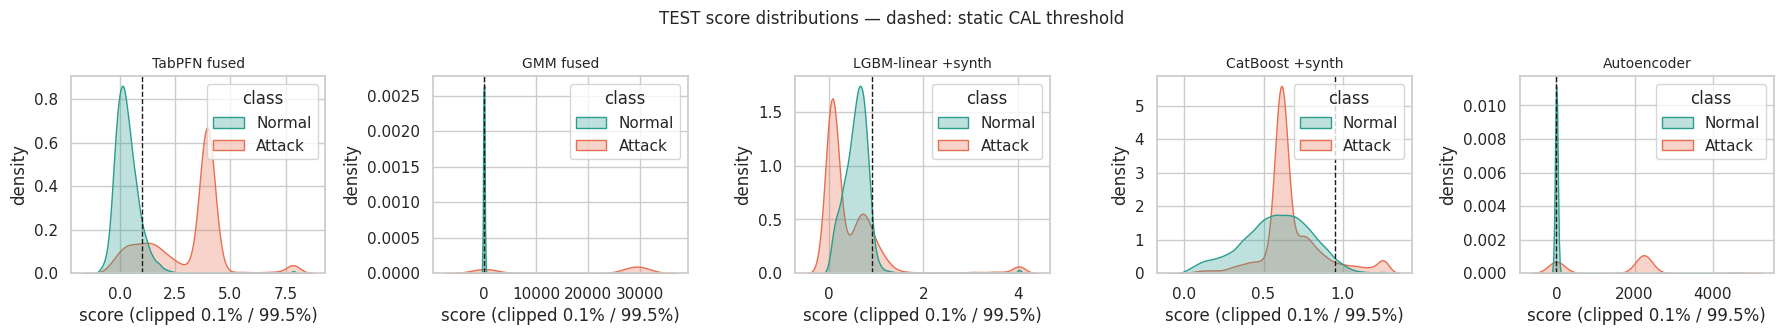

In [33]:
fig, axes = plt.subplots(1, len(CORE), figsize=(3.6 * len(CORE), 3.4), squeeze=False)
for ax, m in zip(axes[0], CORE):
    s = score_matrix[m]
    lo, hi = np.quantile(s, [0.001, 0.995])
    frame = pd.DataFrame({"score": np.clip(s, lo, hi), "class": np.where(y_eval == 1, "Attack", "Normal")})
    sns.kdeplot(data=frame, x="score", hue="class", hue_order=["Normal", "Attack"], common_norm=False,
                fill=True, alpha=0.3, palette={"Normal": "#2a9d8f", "Attack": "#e76f51"}, warn_singular=False, ax=ax)
    ax.axvline(THRESHOLDS[m], color="k", ls="--", lw=1)
    ax.set_title(m, fontsize=10)
    ax.set(xlabel="score (clipped 0.1% / 99.5%)", ylabel="density")
fig.suptitle("TEST score distributions — dashed: static CAL threshold", fontsize=12)
plt.tight_layout()
save_fig(fig, "score_distributions")
plt.show()

figure saved: output-figures/score_timeline_v3.png


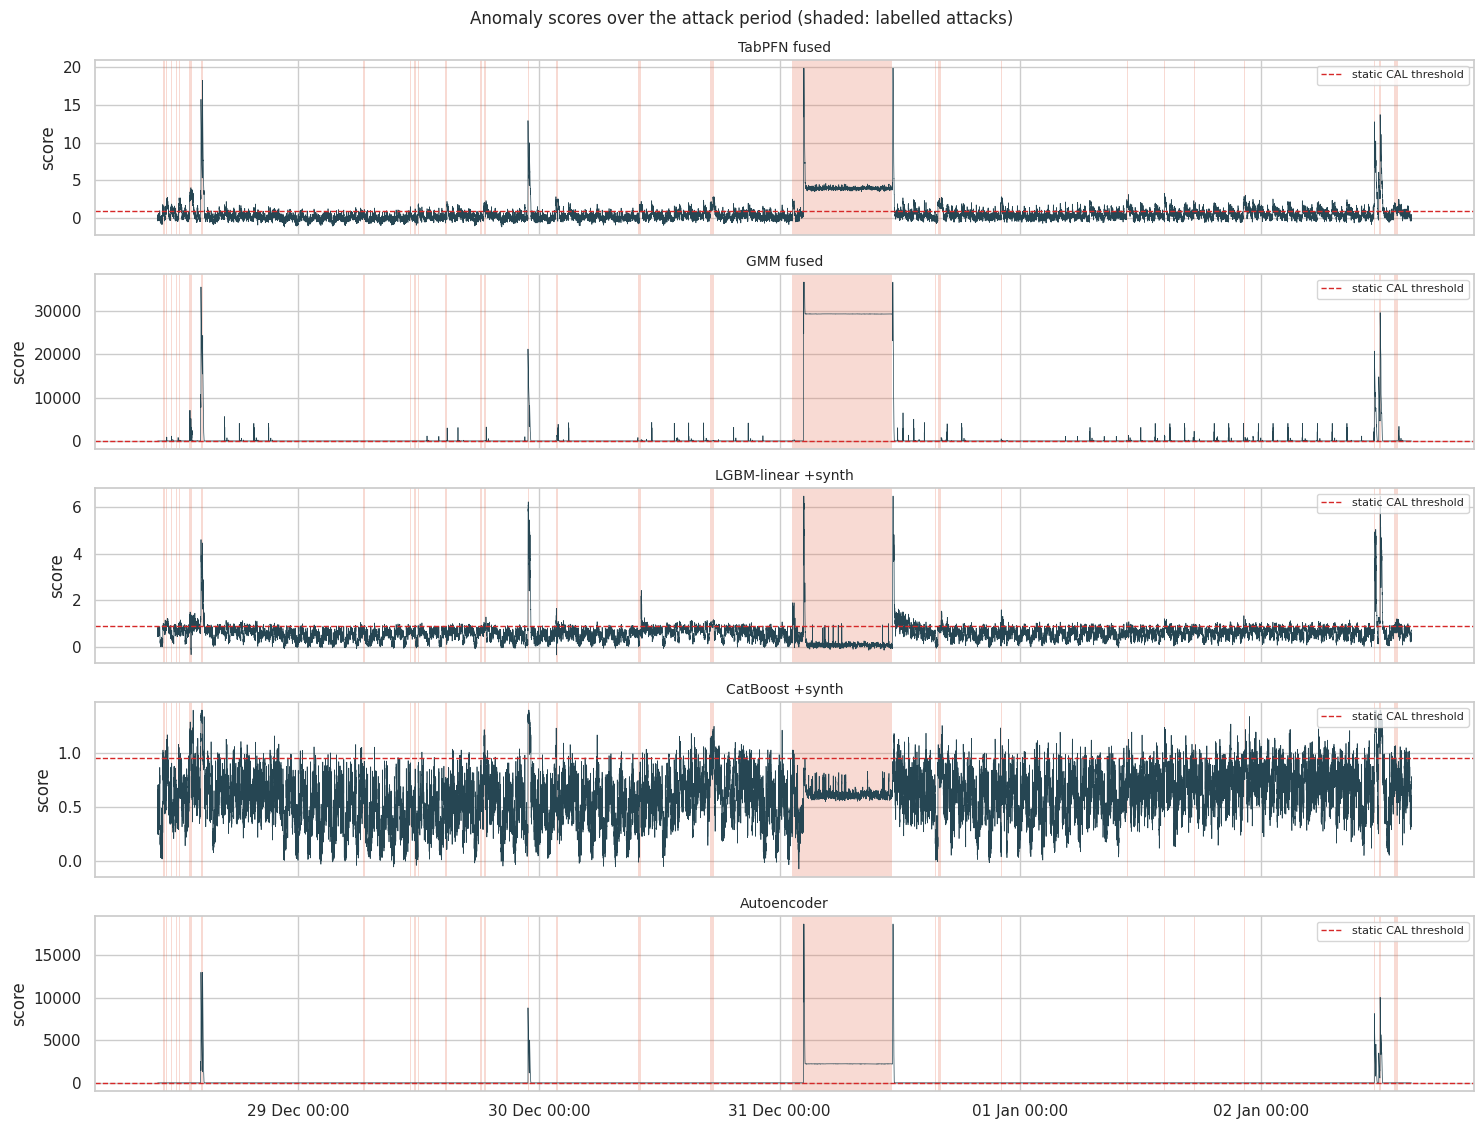

In [34]:
fig, axes = plt.subplots(len(CORE), 1, figsize=(15, 2.3 * len(CORE)), sharex=True, squeeze=False)
for ax, m in zip(axes[:, 0], CORE):
    s = score_matrix[m]
    ax.plot(ts_eval, np.clip(s, None, np.quantile(s, 0.999)), lw=0.5, color="#264653")
    ax.axhline(THRESHOLDS[m], color="#d62828", ls="--", lw=1, label="static CAL threshold")
    shade_attacks(ax, ev_segments)
    ax.set_ylabel("score")
    ax.set_title(m, fontsize=10)
    ax.legend(loc="upper right", fontsize=8)
axes[-1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%d %b %H:%M"))
fig.suptitle("Anomaly scores over the attack period (shaded: labelled attacks)", fontsize=12)
plt.tight_layout()
save_fig(fig, "score_timeline")
plt.show()

### **E6. False-alarm rate per test day: static vs. adaptive threshold (change 6)**

This is the direct measure of threshold transfer. Calibrated at 1% on CAL, a drift-free detector stays near 1% every day. v2 reached 99% (TabPFN level) and 26% (TabPFN detrend) by 2 Jan.

figure saved: output-figures/daily_false_alarm_rate_v3.png


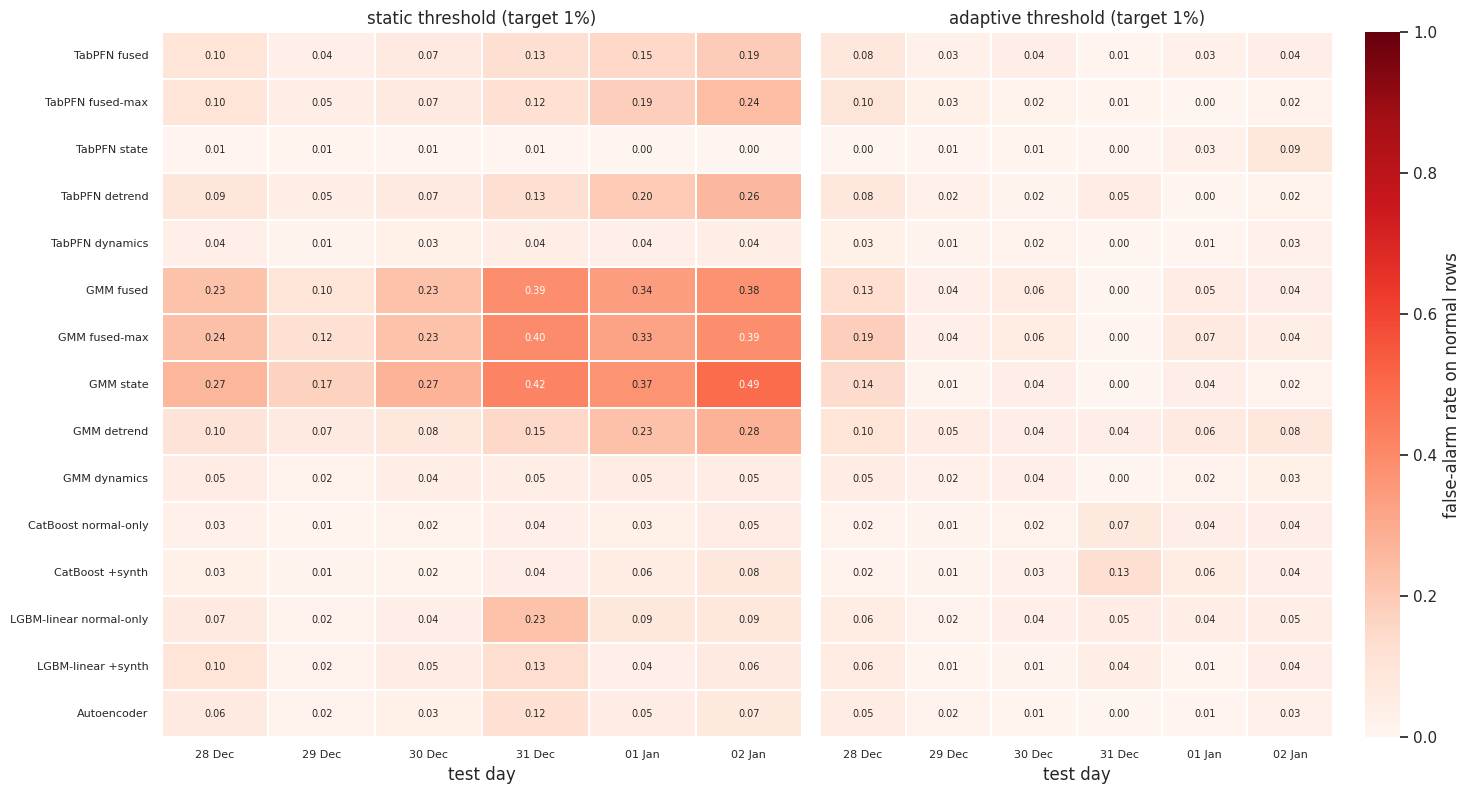

In [35]:
daily = {mode: pd.DataFrame({m: daily_false_alarm_rate(ts_eval, y_eval, s >= t) for m, (s, t) in src.items()}).T
         for mode, src in {"static": {m: (score_matrix[m], THRESHOLDS[m]) for m in names},
                           "adaptive": ADAPTIVE}.items()}
for mode, frame in daily.items():
    frame.columns = [pd.Timestamp(c).strftime("%d %b") for c in frame.columns]
    frame.to_csv(RUN_DIR / f"results_daily_false_alarm_rate_{mode}.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 0.38 * len(names) + 2.4), sharey=True)
for ax, (mode, frame) in zip(axes, daily.items()):
    sns.heatmap(frame.loc[names], annot=True, fmt=".2f", annot_kws={"size": 7}, cmap="Reds", vmin=0, vmax=1,
                linewidths=0.3, cbar=ax is axes[-1], cbar_kws={"label": "false-alarm rate on normal rows"}, ax=ax)
    ax.set(xlabel="test day", ylabel="", title=f"{mode} threshold (target {target_fpr:.0%})")
    ax.tick_params(labelsize=8)
plt.tight_layout()
save_fig(fig, "daily_false_alarm_rate")
plt.show()

### **E7. Rank agreement and cost**

Single-record latency is measured as a gateway would call the model, one row at a time. Online feature cost is one sensor read plus a running mean (600 s) and a running variance (60 s) per sensor.

figure saved: output-figures/spearman_rank_v3.png


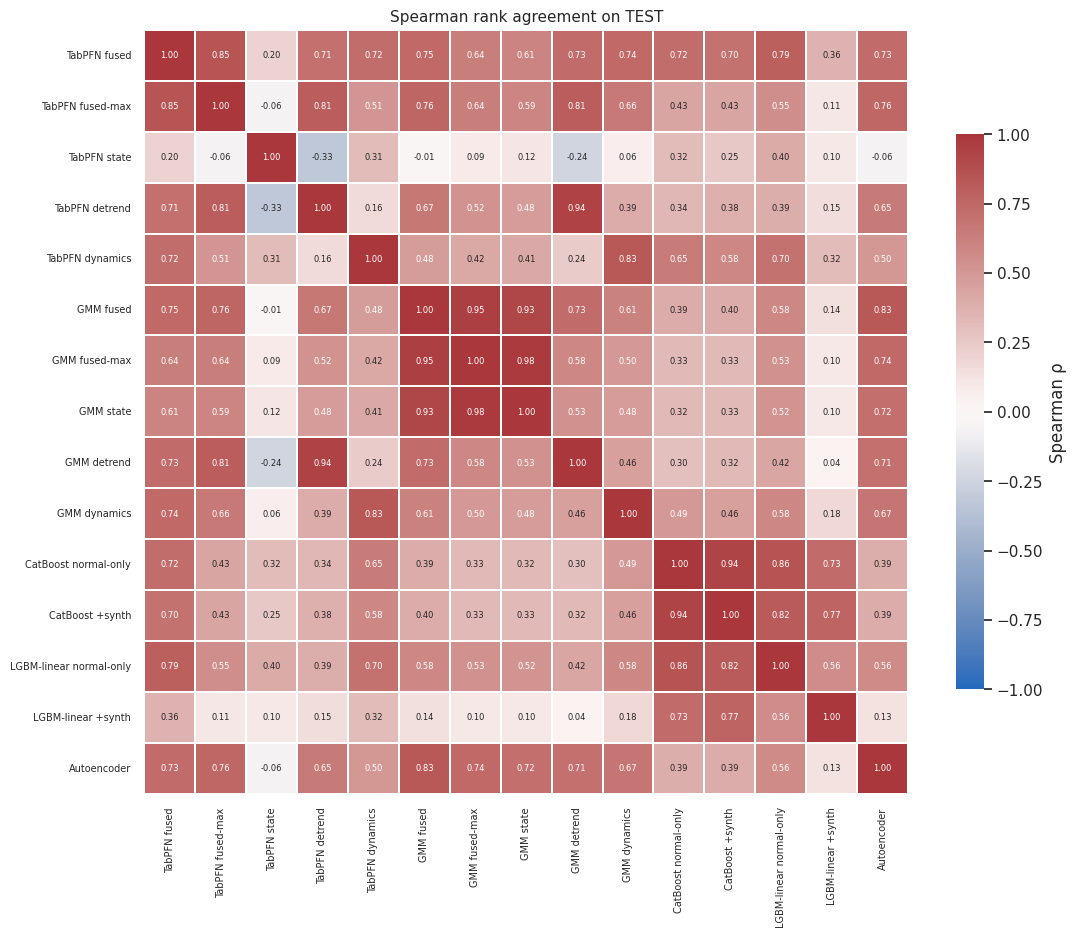

,model,ms_per_row
0,"TabPFN state (3 seeds, 28 features, GPU, batched)",56.5458
1,"TabPFN detrend (3 seeds, 16 features, GPU, bat...",30.0684
2,"TabPFN dynamics (3 seeds, 16 features, GPU, ba...",30.1326
3,"TabPFN fused (all views, GPU, batched)",116.7469
4,"GMM fused (all views, CPU, batched)",0.0093
5,"CatBoost (CPU, single record p50)",0.4220
6,"CatBoost (CPU, single record p99)",0.7263
7,"CatBoost (CPU, batched)",0.0009
8,"LGBM-linear (CPU, single record p50)",0.7248
9,"LGBM-linear (CPU, single record p99)",1.2698


In [36]:
corr = pd.DataFrame(score_matrix).corr(method="spearman")
fig, ax = plt.subplots(figsize=(0.55 * len(names) + 3, 0.5 * len(names) + 2))
sns.heatmap(corr, annot=True, fmt=".2f", annot_kws={"size": 6}, cmap="vlag", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.3, cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
ax.tick_params(labelsize=7)
ax.set_title("Spearman rank agreement on TEST", fontsize=11)
plt.tight_layout()
save_fig(fig, "spearman_rank")
plt.show()

surrogate_files = json.loads((SURROGATE_DIR / "surrogate_config.json").read_text())
features_eval = surrogate_files["features"]
X_one = ev_test[features_eval].iloc[:2000].to_numpy()
loaded = {}
for model_name, label in SURROGATE_LABEL.items():
    stem = f"{model_name}__synthetic" if "synthetic" in cfg["surrogate_config"]["train_sets"] else f"{model_name}__normal"
    path = SURROGATE_DIR / (f"{stem}.cbm" if model_name == "catboost" else f"{stem}.txt")
    if path.exists():
        loaded[label] = (CatBoostRegressor().load_model(str(path)) if model_name == "catboost"
                         else lgb.Booster(model_file=str(path)))
teacher_cost = pd.read_csv(TEACHER_DIR / "teacher_cost.csv")
cost_rows = [{"model": f"TabPFN {v} ({len(g)} seeds, {int(g['n_features'].iloc[0])} features, GPU, batched)",
              "ms_per_row": g["ms_per_row"].sum()} for v, g in teacher_cost.groupby("view", sort=False)]
cost_rows.append({"model": "TabPFN fused (all views, GPU, batched)", "ms_per_row": teacher_cost["ms_per_row"].sum()})
gmm_summary = pd.read_csv(RUN_DIR / "gmm_summary.csv")
cost_rows.append({"model": "GMM fused (all views, CPU, batched)", "ms_per_row": gmm_summary["ms_per_row_batched"].sum()})
for name, model in loaded.items():
    for row in X_one[:50]:
        model.predict(row.reshape(1, -1))      # warm-up
    lat = []
    for row in X_one:
        t0 = time.perf_counter(); model.predict(row.reshape(1, -1)); lat.append(time.perf_counter() - t0)
    lat_ms = 1000 * np.array(lat)
    t0 = time.perf_counter(); model.predict(ev_test[features_eval].to_numpy()); batch_ms = 1000 * (time.perf_counter() - t0) / len(ev_test)
    cost_rows += [{"model": f"{name} (CPU, single record p50)", "ms_per_row": np.percentile(lat_ms, 50)},
                  {"model": f"{name} (CPU, single record p99)", "ms_per_row": np.percentile(lat_ms, 99)},
                  {"model": f"{name} (CPU, batched)", "ms_per_row": batch_ms}]
cost = pd.DataFrame(cost_rows)
cost.to_csv(RUN_DIR / "results_cost.csv", index=False)
display(cost.round(4))

## **F. Final ROC/AUC evaluation: TabPFN teacher vs. GMM baseline vs. surrogate**

The headline comparison of the paper, on the same TEST rows, labels and protocol:

| role | method |
|---|---|
| **Teacher** | TabPFN fused (mean of the CAL-calibrated state, detrend and dynamics teachers) |
| **Classical density baseline** | GMM fused (same views, same scaler, same fusion) |
| **Deployable surrogate** | the primary surrogate (`SURROGATE_CONFIG["primary"]`), distilled from the teacher |

The per-view teachers and GMMs are shown too, so the gain or loss can be traced to a view.

Metrics:
- **ROC-AUC** and **average precision**, with 95% block-bootstrap CIs (threshold-free).
- **pAUC** at FPR ≤ 10%, McClish-standardised: 0.5 = random, 1 = perfect. This is the region an operator can live with.
- **TPR at 1% FPR**: the ROC operating point. It uses labels, so it is an upper bound, not a deployable threshold.
- The **deployable** operating point at the static and adaptive CAL thresholds: test FPR, recall, attacks.

In [37]:
FINAL = [m for m in ["TabPFN fused", "GMM fused", PRIMARY_SURROGATE] if m in names]
PER_VIEW = [m for v in view_names for m in (f"TabPFN {v}", f"GMM {v}") if m in names]
OTHER_SURR = [m for m in names if m.split()[0] in ("CatBoost", "LGBM-linear") and m != PRIMARY_SURROGATE]
final_methods = FINAL + PER_VIEW + ["TabPFN fused-max", "GMM fused-max"] + OTHER_SURR + ["Autoencoder"]
final_methods = [m for m in dict.fromkeys(final_methods) if m in names]
role = {m: ("teacher" if m.startswith("TabPFN") else "GMM baseline" if m.startswith("GMM")
            else "autoencoder" if m == "Autoencoder" else "surrogate") for m in final_methods}

res = main_results.set_index(["method", "threshold_mode"])
final_rows = []
for m in final_methods:
    s = score_matrix[m]
    auc_lo, auc_hi = np.quantile(boot[f"auc|{m}"], [0.025, 0.975])
    ap_lo, ap_hi = np.quantile(boot[f"ap|{m}"], [0.025, 0.975])
    st, ad = res.loc[(m, "static")], res.loc[(m, "adaptive")]
    final_rows.append({
        "method": m, "role": role[m],
        "roc_auc": roc_auc_score(y_eval, s), "auc_ci_low": auc_lo, "auc_ci_high": auc_hi,
        "average_precision": average_precision_score(y_eval, s), "ap_ci_low": ap_lo, "ap_ci_high": ap_hi,
        f"pauc_fpr<={ecfg['pauc_max_fpr']}": roc_auc_score(y_eval, s, max_fpr=ecfg["pauc_max_fpr"]),
        "tpr@fpr=1% (oracle)": tpr_at_fpr(y_eval, s, 0.01),
        "static: test_fpr": st["test_fpr"], "static: recall": st["recall"], "static: attacks": int(st["attacks_detected"]),
        "adaptive: roc_auc": roc_auc_score(y_eval, np.nan_to_num(ADAPTIVE[m][0], nan=0.0)),
        "adaptive: test_fpr": ad["test_fpr"], "adaptive: recall": ad["recall"], "adaptive: attacks": int(ad["attacks_detected"]),
    })
final_table = pd.DataFrame(final_rows).set_index("method")
final_table.to_csv(RUN_DIR / "results_final_roc_auc.csv")
display(final_table.round(4))

,role,roc_auc,auc_ci_low,auc_ci_high,average_precision,ap_ci_low,ap_ci_high,pauc_fpr<=0.1,tpr@fpr=1% (oracle),static: test_fpr,static: recall,static: attacks,adaptive: roc_auc,adaptive: test_fpr,adaptive: recall,adaptive: attacks
method,,,,,,,,,,,,,,,,
TabPFN fused,teacher,0.9124,0.8539,0.9544,0.7266,0.5751,0.8377,0.8557,0.6708,0.1065,0.8299,28,0.9007,0.0371,0.6183,24
GMM fused,GMM baseline,0.9318,0.8843,0.9674,0.8285,0.6846,0.9138,0.8749,0.6534,0.2654,0.9236,30,0.9095,0.0510,0.6829,26
LGBM-linear +synth,surrogate,0.3138,0.2049,0.4721,0.1395,0.0952,0.2032,0.5357,0.0558,0.0589,0.1355,27,0.3483,0.0245,0.1068,21
TabPFN state,teacher,0.7981,0.6818,0.8854,0.7025,0.5007,0.8315,0.8059,0.6176,0.0060,0.6167,9,0.7984,0.0208,0.6231,11
GMM state,GMM baseline,0.9246,0.8684,0.9662,0.8341,0.6946,0.9195,0.8795,0.6774,0.3190,0.9045,30,0.9016,0.0395,0.6489,25
TabPFN detrend,teacher,0.7347,0.6959,0.7758,0.2475,0.1816,0.3151,0.5513,0.0761,0.1253,0.2286,24,0.6872,0.0270,0.1282,20
GMM detrend,GMM baseline,0.8693,0.8276,0.9036,0.4219,0.3202,0.5199,0.6032,0.0757,0.1461,0.8815,25,0.8247,0.0583,0.2275,25
TabPFN dynamics,teacher,0.8955,0.8241,0.9463,0.7929,0.6328,0.8863,0.8624,0.6651,0.0329,0.7288,28,0.8832,0.0154,0.5521,23
GMM dynamics,GMM baseline,0.9049,0.8402,0.9497,0.7915,0.6259,0.8863,0.8540,0.6637,0.0422,0.7184,27,0.8884,0.0267,0.5693,24


figure saved: output-figures/roc_final_v3.png


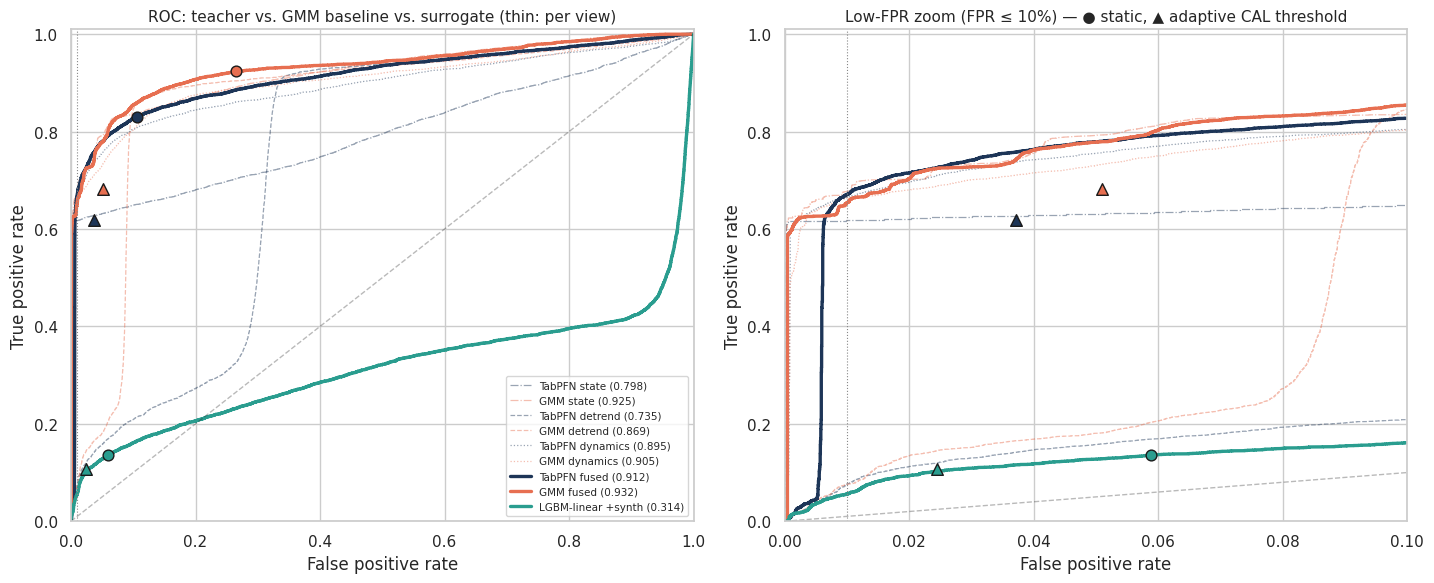

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 6))
final_style = {"TabPFN fused": ("#1d3557", "-"), "GMM fused": ("#e76f51", "-"), PRIMARY_SURROGATE: ("#2a9d8f", "-")}
for ax, xmax in zip(axes, [1.0, 0.10]):
    for m in PER_VIEW:
        f, t_, _ = roc_curve(y_eval, score_matrix[m])
        c = "#1d3557" if m.startswith("TabPFN") else "#e76f51"
        ax.plot(f, t_, lw=0.9, ls=":" if "dynamics" in m else "--" if "detrend" in m else "-.", color=c, alpha=0.45,
                label=f"{m} ({roc_auc_score(y_eval, score_matrix[m]):.3f})" if xmax == 1.0 else None)
    for m in FINAL:
        color, ls = final_style[m]
        f, t_, _ = roc_curve(y_eval, score_matrix[m])
        ax.plot(f, t_, lw=2.4, ls=ls, color=color, label=f"{m} ({roc_auc_score(y_eval, score_matrix[m]):.3f})")
        r = res.loc[(m, "static")]
        ax.scatter([r["test_fpr"]], [r["recall"]], color=color, s=60, marker="o", edgecolor="k", zorder=5)
        r = res.loc[(m, "adaptive")]
        ax.scatter([r["test_fpr"]], [r["recall"]], color=color, s=70, marker="^", edgecolor="k", zorder=5)
    ax.plot([0, 1], [0, 1], "k--", alpha=0.3, lw=1)
    ax.axvline(target_fpr, color="#888", lw=0.8, ls=":")
    ax.set(xlim=(0, xmax), ylim=(0, 1.01), xlabel="False positive rate", ylabel="True positive rate")
axes[0].set_title("ROC: teacher vs. GMM baseline vs. surrogate (thin: per view)", fontsize=11)
axes[1].set_title("Low-FPR zoom (FPR ≤ 10%) — ● static, ▲ adaptive CAL threshold", fontsize=11)
axes[0].legend(fontsize=7.5, loc="lower right")
plt.tight_layout()
save_fig(fig, "roc_final")
plt.show()

### **F2. Paired AUC differences**

Δ = AUC(A) − AUC(B) on the same bootstrap replicates (95% CI). A difference is supported when its block-bootstrap CI excludes 0. DeLong p-values assume independent rows, which is optimistic on autocorrelated data, so they are shown only for reference.

,comparison,delta_auc,ci_low,ci_high,ci_excludes_0,delong_p (iid)
0,TabPFN fused − GMM fused,-0.0194,-0.0453,0.0005,False,0.0
1,TabPFN fused − LGBM-linear +synth,0.5986,0.3996,0.7383,True,0.0
2,LGBM-linear +synth − GMM fused,-0.6180,-0.7561,-0.4258,True,0.0
3,TabPFN state − GMM state,-0.1265,-0.2088,-0.0676,True,0.0
4,TabPFN detrend − GMM detrend,-0.1347,-0.1728,-0.0885,True,0.0
5,TabPFN dynamics − GMM dynamics,-0.0094,-0.0299,0.0065,False,0.0
6,CatBoost +synth − CatBoost normal-only,-0.0411,-0.0703,-0.0013,True,0.0
7,LGBM-linear +synth − LGBM-linear normal-only,-0.5733,-0.7146,-0.3802,True,0.0
8,TabPFN fused − TabPFN state,0.1143,0.0581,0.1916,True,0.0
9,TabPFN fused − TabPFN detrend,0.1777,0.1084,0.2341,True,0.0


figure saved: output-figures/auc_differences_final_v3.png


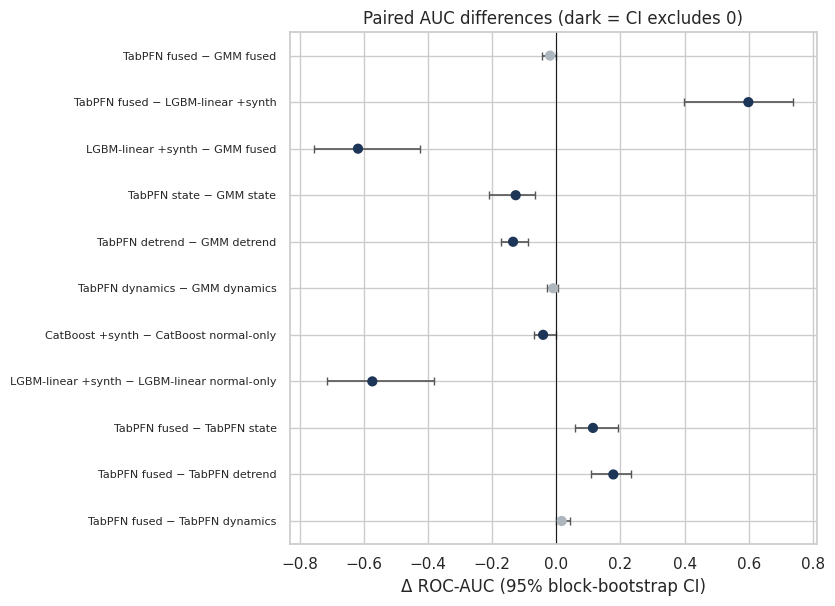

In [39]:
pairs = [("TabPFN fused", "GMM fused"),
         ("TabPFN fused", PRIMARY_SURROGATE),
         (PRIMARY_SURROGATE, "GMM fused")]
pairs += [(f"TabPFN {v}", f"GMM {v}") for v in view_names]
pairs += [(f"{lab} +synth", f"{lab} normal-only") for lab in SURROGATE_LABEL.values()]
pairs += [("TabPFN fused", f"TabPFN {v}") for v in view_names]
pairs = [(a, b) for a, b in pairs if a in names and b in names]

diff_rows = []
for a, b in pairs:
    d = boot[f"auc|{a}"] - boot[f"auc|{b}"]
    lo, hi = np.quantile(d, [0.025, 0.975])
    dl = delong_test(y_eval, score_matrix[a], score_matrix[b])
    diff_rows.append({"comparison": f"{a} − {b}", "delta_auc": dl["delta"], "ci_low": lo, "ci_high": hi,
                      "ci_excludes_0": not (lo <= 0 <= hi), "delong_p (iid)": dl["p_value"]})
final_diffs = pd.DataFrame(diff_rows)
final_diffs.to_csv(RUN_DIR / "results_final_auc_differences.csv", index=False)
display(final_diffs.round(4))

fig, ax = plt.subplots(figsize=(8.5, 0.42 * len(final_diffs) + 1.6))
ypos = np.arange(len(final_diffs))
colors = np.where(final_diffs["ci_excludes_0"], "#1d3557", "#adb5bd")
ax.errorbar(final_diffs["delta_auc"], ypos, xerr=[final_diffs["delta_auc"] - final_diffs["ci_low"],
            final_diffs["ci_high"] - final_diffs["delta_auc"]], fmt="none", ecolor="#555", capsize=3, lw=1.2)
ax.scatter(final_diffs["delta_auc"], ypos, c=colors, s=40, zorder=3)
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(ypos)
ax.set_yticklabels(final_diffs["comparison"], fontsize=8)
ax.invert_yaxis()
ax.set(xlabel="Δ ROC-AUC (95% block-bootstrap CI)", title="Paired AUC differences (dark = CI excludes 0)")
plt.tight_layout()
save_fig(fig, "auc_differences_final")
plt.show()

figure saved: output-figures/auc_tabpfn_vs_gmm_v3.png


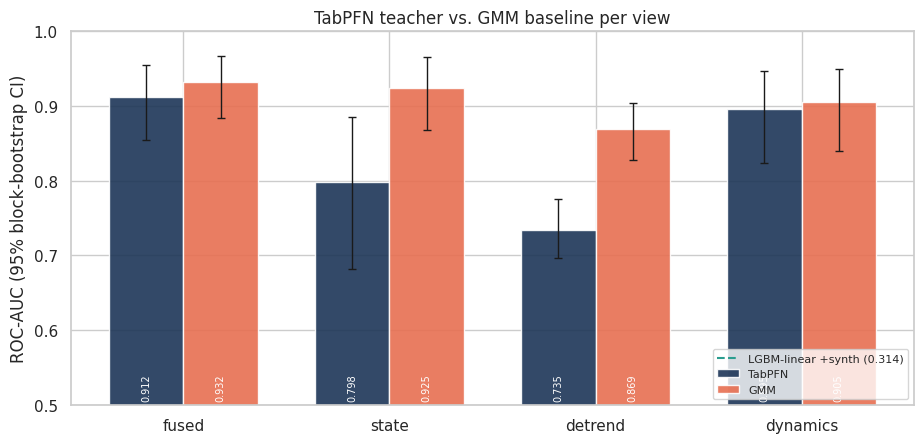

In [40]:
# TabPFN vs. GMM per view, plus the surrogate: AUC with bootstrap CIs.
groups = ["fused"] + view_names
fig, ax = plt.subplots(figsize=(1.6 * len(groups) + 3, 4.6))
width = 0.36
for j, (family, color) in enumerate([("TabPFN", "#1d3557"), ("GMM", "#e76f51")]):
    est, lo, hi = [], [], []
    for g in groups:
        m = f"{family} {g}"
        est.append(roc_auc_score(y_eval, score_matrix[m]))
        q = np.quantile(boot[f"auc|{m}"], [0.025, 0.975]); lo.append(q[0]); hi.append(q[1])
    x = np.arange(len(groups)) + (j - 0.5) * width
    ax.bar(x, est, width, color=color, label=family, alpha=0.9)
    ax.errorbar(x, est, yerr=[np.array(est) - lo, np.array(hi) - est], fmt="none", ecolor="k", capsize=3, lw=1)
    for xi, e in zip(x, est):
        ax.text(xi, 0.505, f"{e:.3f}", ha="center", va="bottom", fontsize=7, color="white", rotation=90)
if PRIMARY_SURROGATE in names:
    s_auc = roc_auc_score(y_eval, score_matrix[PRIMARY_SURROGATE])
    ax.axhline(s_auc, color="#2a9d8f", ls="--", lw=1.5, label=f"{PRIMARY_SURROGATE} ({s_auc:.3f})")
ax.set_xticks(np.arange(len(groups)))
ax.set_xticklabels(groups)
ax.set(ylim=(0.5, 1.0), ylabel="ROC-AUC (95% block-bootstrap CI)", title="TabPFN teacher vs. GMM baseline per view")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
save_fig(fig, "auc_tabpfn_vs_gmm")
plt.show()

### **F3. How to read the final evaluation**

Answer the three paper questions from §F1–F2, in this order:
1. **Does the foundation-model density beat a classical one?** Look at `TabPFN fused − GMM fused` and the per-view rows. In v2 they were tied on the level view. A CI that excludes 0 in TabPFN's favour, in at least the fused comparison, is the evidence the paper needs. If it doesn't, report TabPFN as *matching* a GMM, the honest result.
2. **Is the surrogate a faithful, deployable copy?**
   - Look at `TabPFN fused − surrogate`: smaller is better, and below ~0.03 is a usable distillation.
   - Look at `+synth − normal-only`: this is the Plan §5 ablation, and should be positive.
   - Check the cost table (E7) for the speed-up.
3. **Does the threshold hold?** Compare the ● static and ▲ adaptive markers in the zoomed ROC with the daily false-alarm heatmap (E6). A method is deployable only if its adaptive-threshold FPR stays within a small multiple of 1% on every day.

## **G. Results and figures manifest**

In [41]:
manifest = pd.DataFrame(
    [{"file": p.relative_to(RUN_DIR).as_posix(), "MB": round(p.stat().st_size / 1e6, 3)}
     for p in sorted(RUN_DIR.rglob("*")) if p.is_file()]
    + [{"file": p.as_posix(), "MB": round(p.stat().st_size / 1e6, 3)}
       for p in sorted(FIG_DIR.glob(f"*_{FIG_VERSION}.png"))]
)
display(manifest)
print(f"Run directory: {RUN_DIR.resolve()} | run {RUN_FINGERPRINT} | teacher {TEACHER_FINGERPRINT}")
print(f"Figures: {FIG_DIR.resolve()} ({len(list(FIG_DIR.glob(f'*_{FIG_VERSION}.png')))} files, {FIG_DPI} dpi)")

,file,MB
0,ae_cal.parquet,0.081
1,ae_test.parquet,0.268
2,bootstrap_replicates.parquet,0.298
3,config.json,0.004
4,diagnostic_unseen_actuator_states.csv,0.000
...,...,...
85,output-figures/split_and_views_v3.png,2.073
86,output-figures/surrogate_fidelity_v3.png,3.205
87,output-figures/surrogate_importance_v3.png,0.521
88,output-figures/teacher_roc_daily_v3.png,0.802


Run directory: /home/jaume/_DEVELOPMENT/_projects/tabular-IDS/results/SWaT_A1A2-full-pipeline-v3 | run bf936a2bb2 | teacher fe81f1e75c
Figures: /home/jaume/_DEVELOPMENT/_projects/tabular-IDS/output-figures (16 files, 600 dpi)


## **Conclusions and next steps (run `bf936a2bb2`, teacher 4 permutations × 3 seeds)**

### Headline: TabPFN teacher vs. GMM baseline vs. surrogate (TEST, 35 attacks, 1 h block-bootstrap 95% CI)
| method | ROC-AUC [CI] | AP | pAUC (FPR ≤ 0.1) | TPR @ 1% FPR (oracle) | static FPR / recall / attacks | adaptive FPR / recall / attacks | cost (ms/row) |
|---|---|---|---|---|---|---|---|
| **GMM fused** | **0.932** [0.884, 0.967] | **0.83** | **0.875** | 0.653 | 0.265 / 0.92 / 30 | 0.051 / 0.68 / 26 | **0.009** (CPU) |
| Autoencoder | 0.918 [0.860, 0.956] | 0.74 | 0.856 | 0.643 | 0.054 / 0.78 / 23 | 0.016 / 0.58 / 19 | — |
| **TabPFN fused** | 0.912 [0.854, 0.954] | 0.73 | 0.856 | **0.671** | **0.107** / 0.83 / 28 | **0.037** / 0.62 / 24 | 117 (GPU) |
| LGBM-linear normal-only | 0.887 [0.822, 0.934] | 0.59 | 0.798 | 0.093 | 0.078 / 0.80 / 23 | 0.039 / 0.60 / 23 | 0.7 (single row) |
| LGBM-linear +synth (configured primary) | 0.314 [0.205, 0.472] | 0.14 | 0.536 | 0.056 | 0.059 / 0.14 / 27 | 0.025 / 0.11 / 21 | 0.7 |

### Paired ΔAUC (same bootstrap replicates)
| comparison | ΔAUC | 95% CI | verdict |
|---|---|---|---|
| TabPFN fused − GMM fused | −0.019 | [−0.045, +0.001] | tie, GMM ahead |
| TabPFN dynamics − GMM dynamics | −0.009 | [−0.030, +0.006] | tie |
| TabPFN state − GMM state | −0.127 | [−0.209, −0.068] | **GMM better** |
| TabPFN detrend − GMM detrend | −0.135 | [−0.173, −0.088] | **GMM better** |
| LGBM-linear +synth − normal-only | −0.573 | [−0.715, −0.380] | synthetic augmentation **hurts** |
| CatBoost +synth − normal-only | −0.041 | [−0.070, −0.001] | synthetic augmentation hurts |

The DeLong p-values in `results_final_auc_differences.csv` assume independent rows and are far too optimistic on 10 s autocorrelated data. Only the block-bootstrap CIs are used for the conclusions.

### Conclusions
1. **The foundation-model density does not beat a classical density.** TabPFN fused and GMM fused are statistically tied (CI includes 0), with the GMM ahead on AUC, AP and pAUC. No single view shows a TabPFN advantage. The honest claim is that *TabPFN matches a tuned GMM*, at about **10⁴×** the inference cost (117 ms/row on the GPU vs. 0.009 ms/row on the CPU). An autoencoder (0.918) also matches it.
2. **The views explain the result.**
   - **Dynamics** (60 s log rolling std) is the strongest single view for both models: 0.895 vs. 0.905, equivalent, AP ≈ 0.79.
   - **State** is TabPFN's weak point: 0.80 vs. 0.92, unstable across seeds (0.78 / 0.79 / 0.83), and only 9/35 attacks at the static threshold. The 8 actuators in a state never seen in FIT (67% of attack rows) are scored as very unlikely by the GMM's joint covariance. TabPFN's chain-rule density is smoother and penalises them less.
   - **Detrend** is weak for both (AP 0.25 / 0.42). TabPFN detrend only catches onsets (sustained recall 0.07), confirming the v2 diagnosis.
3. **TabPFN's real advantage is drift robustness under a static threshold, not ranking.**
   - Static CAL threshold: TabPFN fused 10.7% test FPR (daily ≤ 0.19) vs. GMM fused 26.5% (daily up to 0.39).
   - TabPFN also has a slightly higher oracle TPR at 1% FPR (0.671 vs. 0.653).
   - The **adaptive threshold** removes this advantage: both reach about 4–5% FPR with 24 vs. 26 attacks and composite F1 0.691 vs. 0.693, a tie.
   - The adaptive threshold is the most useful deployment contribution of v3: it cuts every method's FPR by 2–6× at the cost of 10–30% of point recall.
4. **Distillation works only without the synthetic corruptions.**
   - LGBM-linear distilled on normal rows keeps **97% of the teacher AUC** (0.887 vs. 0.912; Spearman 0.79 on TEST, 0.63 on attack rows) at sub-millisecond single-row latency.
   - Adding teacher-scored synthetic corruptions **inverted** the LGBM-linear surrogate (AUC 0.31, Spearman on attack rows −0.38). The likely cause is linear-leaf extrapolation outside the corruption range. It also hurt CatBoost (−0.04).
   - The Plan §5 hypothesis is therefore **rejected** in this form, and `primary` should be `lightgbm_linear|normal`.
   - Even the best surrogate stays below the GMM, which is cheaper still.
5. **Coverage.**
   - Both detectors miss #4 (MV-504), #12, #20 (AIT-504) and #29 (P-201).
   - The GMM additionally catches #6 (AIT-202), #18 and #24 (P-203). TabPFN only adds the unlisted event.
   - Median time-to-detect is 5 s for both.
6. **Caveat.** With 35 attacks on one plant, the AUC CIs are about ±0.05. A second dataset is needed before any claim, in either direction.

### Next steps
1. **Replicate on WADI A2 (2019).** `WADI_full_pipeline_v1.ipynb` runs TabPFN vs. GMM with the v3 learnings: the dynamics view, fusion, the adaptive threshold, and bootstrap ΔAUC. This is the test of whether "TabPFN ≈ GMM" generalises.
2. **Fix the surrogate.** Set `primary = lightgbm_linear|normal`. Drop the synthetic augmentation, or keep it only for CatBoost with clipped targets and no linear leaves. Report the surrogate against the GMM, not only against the teacher.
3. **State view.** Encode actuators as categorical/one-hot for TabPFN, or condition the density on the actuator configuration (one teacher per actuator mode or per stage, Plan §3). This is where TabPFN loses most against the GMM.
4. **Dynamics first.** Try multi-scale dynamics (30 / 60 / 300 s) and drop detrend from the fusion, since it dilutes the fused score (TabPFN fused − dynamics is only +0.017).
5. **GMM fairness check.** BIC picked k = 32, the top of the grid, so extend the grid (48, 64) to make sure the baseline is not under-fitted.
6. **Statistics for the paper.** Report attack-level (event) bootstrap CIs alongside the row-block bootstrap, and drop iid DeLong from the tables.
7. **Known limits (unchanged).**
   - Constant-in-FIT actuators are invisible to any density model. The §3 diagnostic shows that a trivial "unseen state" rule would flag 67% of attack rows, but also 14% of normal rows.
   - Attack 27 (10 h) can partly leak into its own 24 h adaptive baseline.
